# Motor Insurance Claims Prediction & Pricing — French MTPL Dataset

**Claim Frequency, Severity and Pure Premium Modelling using Actuarial and Machine Learning Approaches**

**Author:** RAHHAL Fatima Zahrae · [GitHub](https://github.com/rahhalfatimazahrae) · [LinkedIn](https://www.linkedin.com/in/fatima-zahrae-rahhal/)

---

**Goal:** predict motor insurance claim frequency and severity, estimate the expected pure premium, and segment insurance policies according to their predicted risk.

**Data:** French Motor Third-Party Liability (freMTPL2) — two datasets: `freMTPL2freq` (policy characteristics, exposure and claim counts) and `freMTPL2sev` (individual claim amounts).

**Key Results:**
- **Frequency:** Poisson GLM achieved an MAE of 0.0988 and an RMSE of 0.2373.
- **Severity:** Histogram-based Gradient Boosting achieved a lower MAE (1,961.40) than Gamma GLM (2,020.18) on the common test sample.
- **Pure Premium:** estimated portfolio pure premium of 223.27 per exposure unit.
- **Risk Segmentation:** average predicted pure premium increased from 91.08 in the lowest-risk decile to 601.62 in the highest-risk decile.

**Contents**

1. Data Loading & Preparation
2. Data Quality and Consistency Checks
3. Exploratory Data Analysis (EDA)
4. Claim Frequency Modeling
5. Claim Severity Modeling
6. Data Integration and Model Validation
7. Pure Premium Estimation
8. Portfolio Risk Segmentation
9. Final Model Performance
10. Outputs
11. Conclusion and Limitations

---

**Before Running:** download `freMTPL2freq.csv` and `freMTPL2sev.csv` (OpenML datasets 41214 and 41215, or the `CASdatasets` R package) and place them in the project folder, next to this notebook. Install the dependencies using `pip install -r requirements.txt`.

## 1. Data Loading & Preparation

The two CSV files are **not** included in the repository. Place `freMTPL2freq.csv` (policies, exposure, claim counts) and `freMTPL2sev.csv` (individual claim amounts) in the same folder as this notebook.

In [2]:
from pathlib import Path
import urllib.request

# Create the folder used to save project outputs
Path("Insurance_Claims_Pricing").mkdir(exist_ok=True)

# Download the original datasets automatically if they are missing
DATASETS = {
    "freMTPL2freq.csv": "https://huggingface.co/datasets/mabilton/fremtpl2/resolve/main/freMTPL2freq.csv",
    "freMTPL2sev.csv": "https://huggingface.co/datasets/mabilton/fremtpl2/resolve/main/freMTPL2sev.csv",
}

for filename, url in DATASETS.items():
    file_path = Path(filename)
    if file_path.exists() and file_path.stat().st_size > 0:
        print(f"Dataset already available: {filename}")
    else:
        print(f"Downloading {filename} ...")
        urllib.request.urlretrieve(url, file_path)
        if not file_path.exists() or file_path.stat().st_size == 0:
            raise RuntimeError(f"Download failed or produced an empty file: {filename}")
        print(f"Download complete: {filename} ({file_path.stat().st_size / (1024**2):.1f} MB)")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
freq = pd.read_csv("freMTPL2freq.csv")
sev = pd.read_csv("freMTPL2sev.csv")

print("Frequency Dataset:", freq.shape)
print("Severity Dataset:", sev.shape)

display(freq.head())
display(sev.head())

Frequency Dataset: (678013, 12)
Severity Dataset: (26639, 2)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


## 2. Data Quality and Consistency Checks

In [7]:
# 1. Informations générales
print("FREQUENCY DATASET")
freq.info()

print("\nSEVERITY DATASET")
sev.info()

# 2. Missing values
print("\nMissing values - Frequency:")
print(freq.isnull().sum())

print("\nMissing values - Severity:")
print(sev.isnull().sum())

# 3. Duplicates
print("\nDuplicates in Frequency:", freq.duplicated().sum())
print("Duplicates in Severity:", sev.duplicated().sum())

# 4. Statistical summary
display(freq.describe())
display(sev.describe())

FREQUENCY DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   VehPower    678013 non-null  int64  
 4   VehAge      678013 non-null  int64  
 5   DrivAge     678013 non-null  int64  
 6   BonusMalus  678013 non-null  int64  
 7   VehBrand    678013 non-null  object 
 8   VehGas      678013 non-null  object 
 9   Area        678013 non-null  object 
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  object 
dtypes: float64(2), int64(6), object(4)
memory usage: 62.1+ MB

SEVERITY DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405
std,1.641783e+06,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,6.114330e+06,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000


,IDpol,ClaimAmount
count,2.663900e+04,2.663900e+04
mean,2.279864e+06,2.278536e+03
std,1.577202e+06,2.929748e+04
min,1.390000e+02,1.000000e+00
25%,1.087642e+06,6.868100e+02
50%,2.137413e+06,1.172000e+03
75%,3.180162e+06,1.228080e+03
max,6.113971e+06,4.075401e+06


In [8]:
# 1. Vérifier les IDpol répétés
print("Frequency - Repeated IDpol:")
print(freq["IDpol"].duplicated().sum())

print("\nSeverity - Repeated IDpol:")
print(sev["IDpol"].duplicated().sum())

# 2. Inspecter les lignes dupliquées dans Severity
duplicates = sev[sev.duplicated(keep=False)]

display(duplicates.head(15))

# 3. Vérifier les valeurs extrêmes
print("\nClaimAmount:")
print(sev["ClaimAmount"].describe(percentiles=[0.90, 0.95, 0.99]))

# 4. Vérifier les valeurs non positives
print("\nClaimAmount <= 0:", (sev["ClaimAmount"] <= 0).sum())

# 5. Nombre de sinistres par contrat dans Severity
print("\nNumber of claims per policy:")
print(sev.groupby("IDpol").size().value_counts().sort_index().head(10))

Frequency - Repeated IDpol:
0

Severity - Repeated IDpol:
1689


,IDpol,ClaimAmount
42,4023587,1204.0
108,4041886,1204.0
162,4023587,1204.0
192,4055082,1204.0
238,4044981,1204.0
264,4085358,1204.0
296,4037199,1204.0
307,4073123,1204.0
312,4055082,1204.0
315,4044981,1204.0



ClaimAmount:
count    2.663900e+04
mean     2.278536e+03
std      2.929748e+04
min      1.000000e+00
50%      1.172000e+03
90%      2.799072e+03
95%      4.861685e+03
99%      1.679370e+04
max      4.075401e+06
Name: ClaimAmount, dtype: float64

ClaimAmount <= 0: 0

Number of claims per policy:
1     23571
2      1298
3        62
4         5
5         2
6         1
8         1
9         1
11        2
16        1
Name: count, dtype: int64


In [9]:
# 1. Total number of claims in Frequency
total_claims_freq = freq["ClaimNb"].sum()

# 2. Number of claim records in Severity
total_claims_sev = len(sev)

print("Total claims in Frequency:", total_claims_freq)
print("Total records in Severity:", total_claims_sev)

# 3. Number of policies with at least one claim
print("\nPolicies with claims in Frequency:",
      (freq["ClaimNb"] > 0).sum())

print("Unique policies in Severity:",
      sev["IDpol"].nunique())

# 4. Check exact duplicated rows
print("\nExact duplicate rows in Severity:",
      sev.duplicated().sum())

# 5. Check if Severity IDs exist in Frequency
comparison = sev[["IDpol"]].drop_duplicates().merge(
    freq[["IDpol"]],
    on="IDpol",
    how="left",
    indicator=True
)

print("\nSeverity policies not found in Frequency:",
      (comparison["_merge"] == "left_only").sum())

# 6. Compare claims per policy
claims_comparison = sev.groupby("IDpol").size().rename(
    "Severity_Claims"
).to_frame().join(
    freq.set_index("IDpol")["ClaimNb"].rename("Frequency_Claims"),
    how="left"
)

display(claims_comparison.head(10))

Total claims in Frequency: 36102
Total records in Severity: 26639

Policies with claims in Frequency: 34060
Unique policies in Severity: 24950

Exact duplicate rows in Severity: 255

Severity policies not found in Frequency: 6


,Severity_Claims,Frequency_Claims
IDpol,,
139.0,1,1.0
190.0,1,1.0
414.0,1,1.0
424.0,2,2.0
463.0,1,1.0
606.0,1,1.0
622.0,1,1.0
811.0,1,1.0
830.0,1,1.0


In [10]:
# Count claims in Severity for each policy
sev_counts = sev.groupby("IDpol").size().rename("Severity_Claims")

# Compare with Frequency
comparison = freq[["IDpol", "ClaimNb"]].merge(
    sev_counts,
    left_on="IDpol",
    right_index=True,
    how="left"
)

comparison["Severity_Claims"] = (
    comparison["Severity_Claims"].fillna(0).astype(int)
)

# Classify the differences
comparison["Status"] = np.select(
    [
        comparison["ClaimNb"] == comparison["Severity_Claims"],
        comparison["Severity_Claims"] < comparison["ClaimNb"],
        comparison["Severity_Claims"] > comparison["ClaimNb"]
    ],
    [
        "Match",
        "Fewer claims in Severity",
        "More claims in Severity"
    ],
    default="Other"
)

print("Comparison by policy:")
print(comparison["Status"].value_counts())

print("\nTotal claims in Frequency:",
      comparison["ClaimNb"].sum())

print("Total claims in Severity:",
      comparison["Severity_Claims"].sum())

print("\nPolicies with different claim counts:")
display(
    comparison[comparison["Status"] != "Match"].head(15)
)

Comparison by policy:
Status
Match                       668896
Fewer claims in Severity      9117
Name: count, dtype: int64

Total claims in Frequency: 36102
Total claims in Severity: 26444

Policies with different claim counts:


,IDpol,ClaimNb,Severity_Claims,Status
0,1.0,1,0,Fewer claims in Severity
1,3.0,1,0,Fewer claims in Severity
2,5.0,1,0,Fewer claims in Severity
3,10.0,1,0,Fewer claims in Severity
4,11.0,1,0,Fewer claims in Severity
5,13.0,1,0,Fewer claims in Severity
6,15.0,1,0,Fewer claims in Severity
7,17.0,1,0,Fewer claims in Severity
8,18.0,1,0,Fewer claims in Severity
9,21.0,1,0,Fewer claims in Severity


In [11]:
# 1. Verify the number of records
print("Severity original rows:", len(sev))
print("Severity grouped rows:", sev.groupby("IDpol").size().sum())

# 2. Find policies present in Severity but absent in Frequency
missing_policies = sev[
    ~sev["IDpol"].isin(freq["IDpol"])
]

print("\nUnmatched Severity rows:", len(missing_policies))
print("Unmatched unique policies:",
      missing_policies["IDpol"].nunique())

# 3. Inspect these policies
display(
    missing_policies.groupby("IDpol").agg(
        Number_of_Claims=("ClaimAmount", "size"),
        Total_ClaimAmount=("ClaimAmount", "sum")
    )
)

Severity original rows: 26639
Severity grouped rows: 26639

Unmatched Severity rows: 195
Unmatched unique policies: 6


,Number_of_Claims,Total_ClaimAmount
IDpol,,
2220367,24,84441.63
2227533,25,64093.76
2262511,66,151800.59
2277846,23,73440.72
2282134,36,330920.05
2286775,21,84017.43


In [12]:
# Keep all original data unchanged

severity_model_data = sev.merge(
    freq,
    on="IDpol",
    how="inner",
    validate="many_to_one"
)

print("Frequency dataset:", freq.shape)
print("Original Severity dataset:", sev.shape)
print("Severity dataset after merging:",
      severity_model_data.shape)

print("\nUnmatched claims:",
      len(sev) - len(severity_model_data))

display(severity_model_data.head())

Frequency dataset: (678013, 12)
Original Severity dataset: (26639, 2)
Severity dataset after merging: (26444, 13)

Unmatched claims: 195


,IDpol,ClaimAmount,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1552,995.20,2,0.59,11,0,39,56,B12,Diesel,D,778,Picardie
1,1010996,1128.12,1,0.95,4,1,49,50,B12,Regular,E,2354,Ile-de-France
2,4024277,1851.11,1,0.71,4,2,32,106,B12,Regular,D,570,Nord-Pas-de-Calais
3,4007252,1204.00,1,0.78,4,1,49,57,B12,Regular,C,288,Midi-Pyrenees
4,4046424,1204.00,1,0.86,12,0,37,50,B12,Diesel,F,27000,Ile-de-France


## 3. Exploratory Data Analysis (EDA)

### 3.1 Claim Frequency Analysis

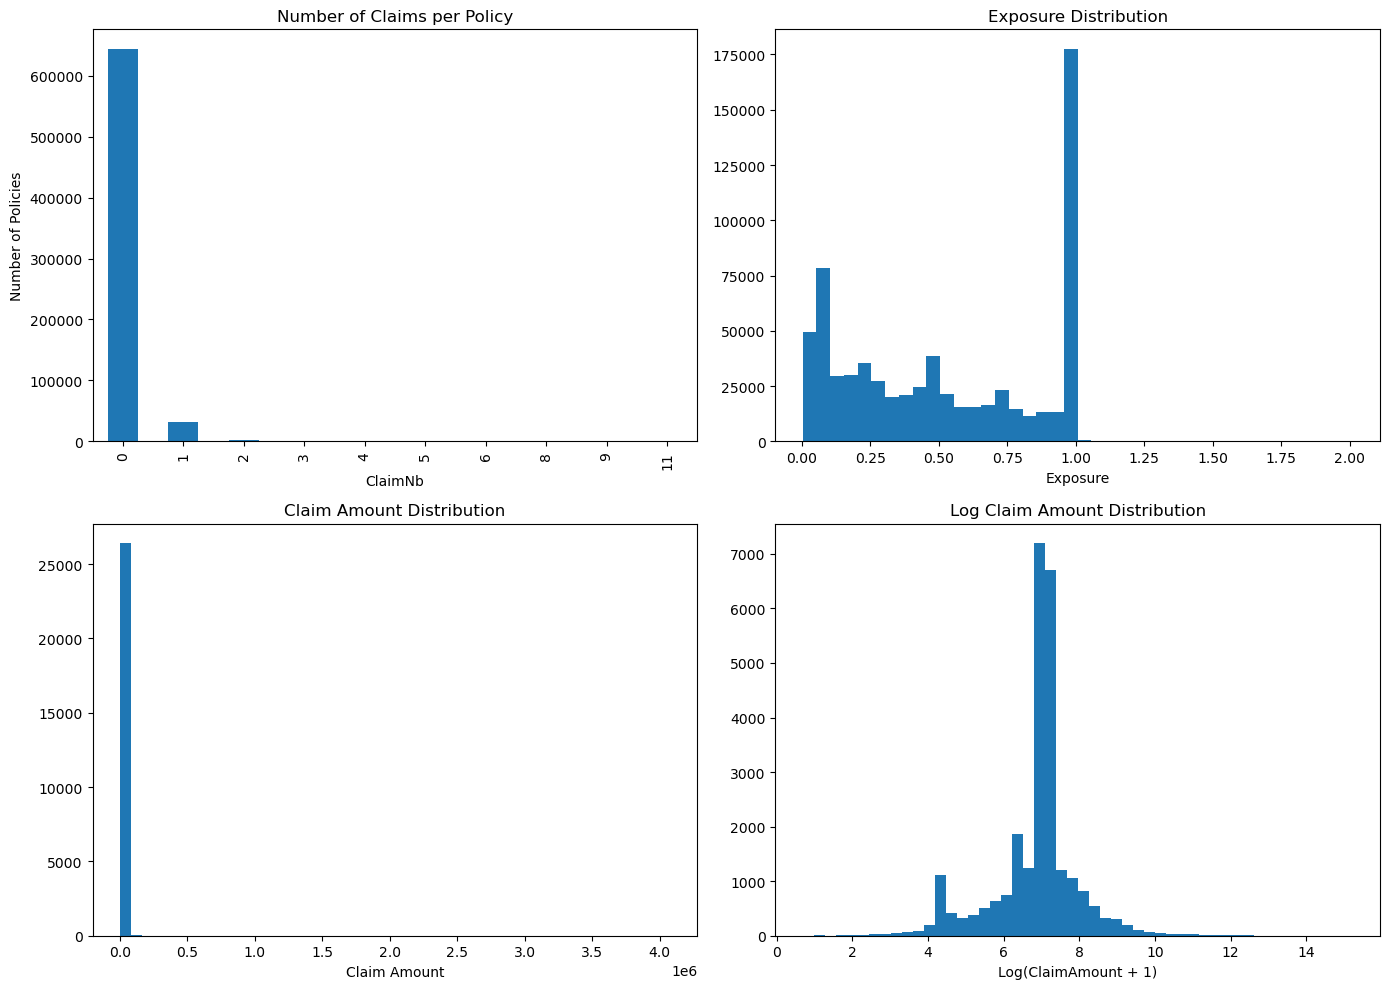

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Number of claims
freq["ClaimNb"].value_counts().sort_index().head(10).plot(
    kind="bar", ax=axes[0, 0]
)
axes[0, 0].set_title("Number of Claims per Policy")
axes[0, 0].set_xlabel("ClaimNb")
axes[0, 0].set_ylabel("Number of Policies")

# 2. Exposure distribution
axes[0, 1].hist(freq["Exposure"], bins=40)
axes[0, 1].set_title("Exposure Distribution")
axes[0, 1].set_xlabel("Exposure")

# 3. Claim amount distribution
axes[1, 0].hist(
    severity_model_data["ClaimAmount"], bins=50
)
axes[1, 0].set_title("Claim Amount Distribution")
axes[1, 0].set_xlabel("Claim Amount")

# 4. Claim amount - log scale
axes[1, 1].hist(
    np.log1p(severity_model_data["ClaimAmount"]), bins=50
)
axes[1, 1].set_title("Log Claim Amount Distribution")
axes[1, 1].set_xlabel("Log(ClaimAmount + 1)")

plt.tight_layout()
plt.show()

In [14]:
# 1. Claim frequency by driver age
risk_by_age = freq.groupby(
    pd.cut(freq["DrivAge"], bins=[17, 25, 35, 45, 55, 65, 100])
).agg(
    Policies=("ClaimNb", "count"),
    Claims=("ClaimNb", "sum"),
    Exposure=("Exposure", "sum")
)

risk_by_age["Frequency"] = (
    risk_by_age["Claims"] / risk_by_age["Exposure"]
)

display(risk_by_age)

# 2. Claim frequency by vehicle age
risk_by_vehicle = freq.groupby("VehAge").agg(
    Policies=("ClaimNb", "count"),
    Claims=("ClaimNb", "sum"),
    Exposure=("Exposure", "sum")
)

risk_by_vehicle["Frequency"] = (
    risk_by_vehicle["Claims"] / risk_by_vehicle["Exposure"]
)

display(risk_by_vehicle.head(15))

# 3. Claim frequency by BonusMalus
risk_by_bonus = freq.groupby(
    pd.cut(freq["BonusMalus"], bins=[0, 50, 70, 90, 110, 150, 250])
).agg(
    Policies=("ClaimNb", "count"),
    Claims=("ClaimNb", "sum"),
    Exposure=("Exposure", "sum")
)

risk_by_bonus["Frequency"] = (
    risk_by_bonus["Claims"] / risk_by_bonus["Exposure"]
)

display(risk_by_bonus)

,Policies,Claims,Exposure,Frequency
DrivAge,,,,
"(17, 25]",38895,2841,16227.903263,0.175069
"(25, 35]",149183,6662,69266.778075,0.096179
"(35, 45]",170352,8397,87702.336287,0.095744
"(45, 55]",161899,9256,89268.776408,0.103687
"(55, 65]",90691,4748,51775.553261,0.091704
"(65, 100]",66993,4198,44258.098167,0.094853


,Policies,Claims,Exposure,Frequency
VehAge,,,,
0,57739,5205,16719.028729,0.311322
1,71284,2931,32749.537619,0.089497
2,59124,2768,29707.489000,0.093175
3,50261,2320,26081.382861,0.088952
4,43492,2282,23759.975715,0.096044
5,38737,2141,22198.765200,0.096447
6,35717,2117,20788.912907,0.101833
7,32880,1999,19254.174346,0.103822
8,32680,1833,19232.314633,0.095308


,Policies,Claims,Exposure,Frequency
BonusMalus,,,,
"(0, 50]",384156,18056,225233.130902,0.080166
"(50, 70]",151375,8224,74483.210513,0.110414
"(70, 90]",97551,5516,41815.392773,0.131913
"(90, 110]",39126,3258,14317.485363,0.227554
"(110, 150]",5596,994,2555.097715,0.389026
"(150, 250]",209,54,95.128197,0.567655


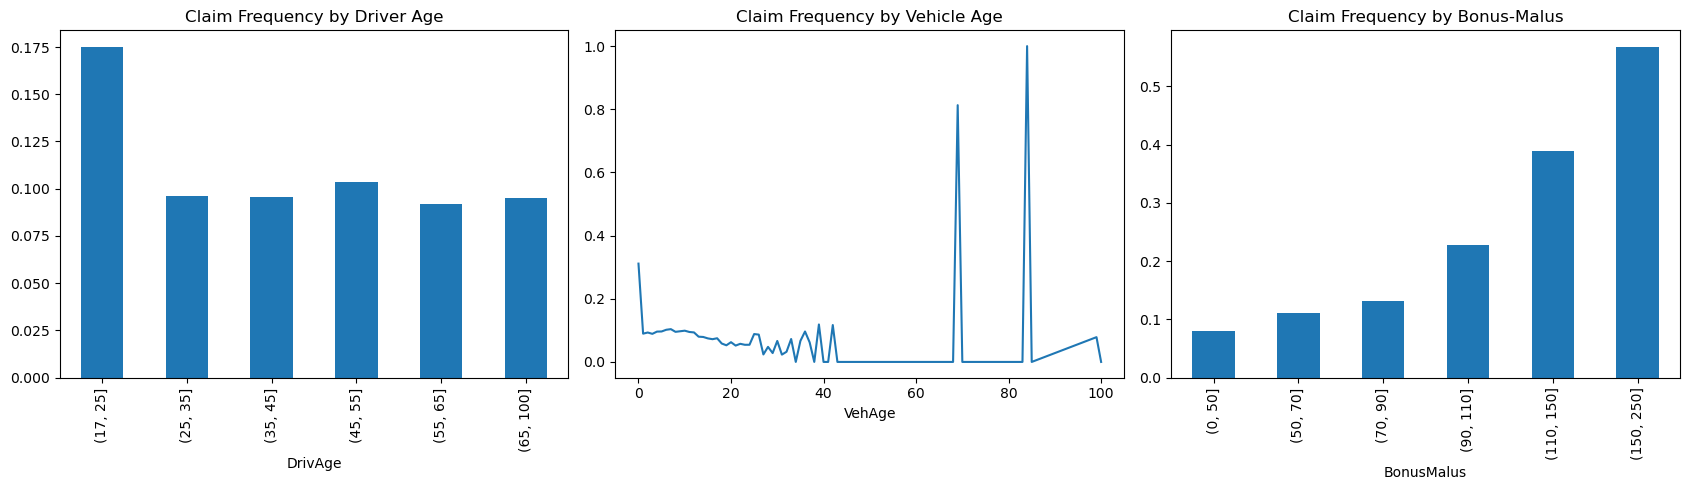

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

risk_by_age["Frequency"].plot(
    kind="bar", ax=axes[0], title="Claim Frequency by Driver Age"
)

risk_by_vehicle["Frequency"].plot(
    kind="line", ax=axes[1], title="Claim Frequency by Vehicle Age"
)

risk_by_bonus["Frequency"].plot(
    kind="bar", ax=axes[2], title="Claim Frequency by Bonus-Malus"
)

plt.tight_layout()
plt.show()

In [16]:
# Categorical risk analysis

categorical_vars = [
    "VehBrand",
    "VehGas",
    "Area",
    "Region"
]

for col in categorical_vars:

    result = freq.groupby(col).agg(
        Policies=("ClaimNb", "count"),
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )

    result["Frequency"] = (
        result["Claims"] / result["Exposure"]
    )

    result = result.sort_values(
        "Frequency", ascending=False
    )

    print(f"\n===== Claim Frequency by {col} =====")
    display(result)


===== Claim Frequency by VehBrand =====


,Policies,Claims,Exposure,Frequency
VehBrand,,,,
B12,166024,8859,64808.608718,0.136695
B11,13585,721,6887.817279,0.104678
B5,34753,2020,19992.062695,0.101040
B3,53395,2818,28592.876331,0.098556
B13,12178,649,6772.032216,0.095835
B4,25179,1312,13775.496080,0.095242
B6,28548,1462,15684.953599,0.093210
B1,162736,8677,95351.059578,0.091001
B10,17707,858,9496.014123,0.090354



===== Claim Frequency by VehGas =====


,Policies,Claims,Exposure,Frequency
VehGas,,,,
Regular,345877,19454,187838.552336,0.103568
Diesel,332136,16648,170660.893126,0.097550



===== Claim Frequency by Area =====


,Policies,Claims,Exposure,Frequency
Area,,,,
F,17954,1131,8129.234074,0.139127
E,137167,7805,63819.314270,0.122298
D,151596,8428,77120.191692,0.109284
C,191880,9875,104449.003784,0.094544
B,75459,3800,43012.323931,0.088347
A,103957,5063,61969.377712,0.081702



===== Claim Frequency by Region =====


,Policies,Claims,Exposure,Frequency
Region,,,,
Corse,4516,247,1765.935399,0.139869
Champagne-Ardenne,3026,160,1205.831509,0.132689
Ile-de-France,69791,3978,30208.641954,0.131684
Picardie,7994,439,3574.410221,0.122817
Rhone-Alpes,84752,5032,45347.417286,0.110966
Alsace,2200,133,1209.115823,0.109998
Provence-Alpes-Cotes-D'Azur,79315,3907,35790.321015,0.109164
Limousin,4567,259,2395.994542,0.108097
Languedoc-Roussillon,35805,1547,14736.104177,0.104980


In [17]:

categorical_vars = ["VehBrand", "VehGas", "Area", "Region"]

for col in categorical_vars:
    result = severity_model_data.groupby(col).agg(
        Number_of_Claims=("ClaimAmount", "count"),
        Mean_Severity=("ClaimAmount", "mean"),
        Median_Severity=("ClaimAmount", "median"),
        Total_Claim_Cost=("ClaimAmount", "sum")
    )

    result = result.sort_values("Mean_Severity", ascending=False)

    print(f"\n===== Claim Severity by {col} =====")
    display(result.round(2))



===== Claim Severity by VehBrand =====


,Number_of_Claims,Mean_Severity,Median_Severity,Total_Claim_Cost
VehBrand,,,,
B11,664,3356.81,1128.12,2228920.37
B2,6805,2762.86,1172.00,18801244.90
B4,1099,2316.97,1128.12,2546351.21
B10,765,2200.39,1165.43,1683301.31
B13,539,2155.16,1172.00,1161629.56
B3,2429,2139.97,1172.00,5197982.07
B1,6898,2096.60,1128.12,14462378.14
B12,4200,2082.64,1204.00,8747094.58
B5,1662,1745.52,1128.12,2901047.93



===== Claim Severity by VehGas =====


,Number_of_Claims,Mean_Severity,Median_Severity,Total_Claim_Cost
VehGas,,,,
Regular,12994,2486.88,1172.0,32314542.55
Diesel,13450,2051.65,1172.0,27594673.95



===== Claim Severity by Area =====


,Number_of_Claims,Mean_Severity,Median_Severity,Total_Claim_Cost
Area,,,,
B,2633,3370.29,1172.0,8873979.52
A,3364,2300.72,1172.0,7739630.67
D,6458,2243.19,1172.0,14486501.16
E,6122,2126.34,1172.0,13017426.30
C,7093,2060.07,1172.0,14612072.43
F,774,1524.04,1172.0,1179606.42



===== Claim Severity by Region =====


,Number_of_Claims,Mean_Severity,Median_Severity,Total_Claim_Cost
Region,,,,
Champagne-Ardenne,77,6249.98,1204.00,481248.34
Corse,132,3519.56,1204.00,464582.55
Centre,6475,2945.92,1128.12,19074802.36
Rhone-Alpes,4233,2428.14,1172.00,10278303.85
Provence-Alpes-Cotes-D'Azur,2986,2301.08,1172.00,6871024.80
Picardie,314,2189.89,1172.00,687624.87
Bretagne,1871,2085.01,1147.46,3901051.25
Basse-Normandie,452,2057.18,1128.12,929847.31
Franche-Comte,38,2014.06,1204.00,76534.11


In [18]:
# Create age groups
severity_model_data["DrivAgeGroup"] = pd.cut(
    severity_model_data["DrivAge"],
    bins=[17, 25, 35, 45, 55, 65, 100]
)

severity_model_data["VehAgeGroup"] = pd.cut(
    severity_model_data["VehAge"],
    bins=[-1, 2, 5, 10, 15, 100]
)

severity_model_data["BonusMalusGroup"] = pd.cut(
    severity_model_data["BonusMalus"],
    bins=[0, 50, 70, 90, 110, 150, 250]
)

# Analyze severity by groups
for col in ["DrivAgeGroup", "VehAgeGroup", "BonusMalusGroup"]:
    result = severity_model_data.groupby(
        col, observed=True
    )["ClaimAmount"].agg(
        Number_of_Claims="count",
        Mean_Severity="mean",
        Median_Severity="median",
        Total_Claim_Cost="sum"
    )

    print(f"\n===== Claim Severity by {col} =====")
    display(result.round(2))


===== Claim Severity by DrivAgeGroup =====


,Number_of_Claims,Mean_Severity,Median_Severity,Total_Claim_Cost
DrivAgeGroup,,,,
"(17, 25]",2403,5121.62,1172.00,12307261.54
"(25, 35]",5167,2052.88,1128.12,10607248.80
"(35, 45]",6315,1919.08,1172.00,12119011.84
"(45, 55]",6622,1861.45,1172.00,12326494.29
"(55, 65]",3316,1890.11,1172.00,6267615.63
"(65, 100]",2621,2396.64,1172.00,6281584.40



===== Claim Severity by VehAgeGroup =====


,Number_of_Claims,Mean_Severity,Median_Severity,Total_Claim_Cost
VehAgeGroup,,,,
"(-1, 2]",5747,2140.19,1172.00,12299662.34
"(2, 5]",5344,1974.72,1172.00,10552899.23
"(5, 10]",8009,1973.41,1159.53,15805071.87
"(10, 15]",5680,3135.27,1128.12,17808346.08
"(15, 100]",1664,2069.25,1172.00,3443236.98



===== Claim Severity by BonusMalusGroup =====


,Number_of_Claims,Mean_Severity,Median_Severity,Total_Claim_Cost
BonusMalusGroup,,,,
"(0, 50]",11592,1922.22,1172.00,22282394.02
"(50, 70]",6692,1960.05,1150.17,13116625.87
"(70, 90]",4518,2169.13,1172.00,9800113.35
"(90, 110]",2656,4802.25,1172.00,12754782.37
"(110, 150]",932,1955.61,1172.00,1822624.48
"(150, 250]",54,2456.97,1172.00,132676.41


### 3.2 Claim Severity Analysis

In [19]:
# Claim Amount distribution
severity_model_data["ClaimAmount"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
).round(2)

count      26444.00
mean        2265.51
std        29371.03
min            1.00
50%         1172.00
75%         1212.38
90%         2767.60
95%         4765.09
99%        16451.22
99.5%      34376.96
max      4075400.56
Name: ClaimAmount, dtype: float64

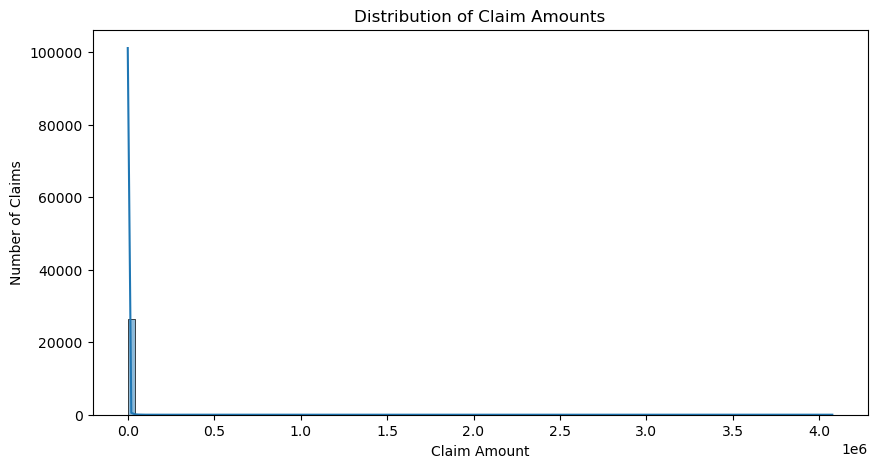

In [20]:
# Visualize claim severity distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    severity_model_data["ClaimAmount"],
    bins=100,
    kde=True
)

plt.title("Distribution of Claim Amounts")
plt.xlabel("Claim Amount")
plt.ylabel("Number of Claims")
plt.show()

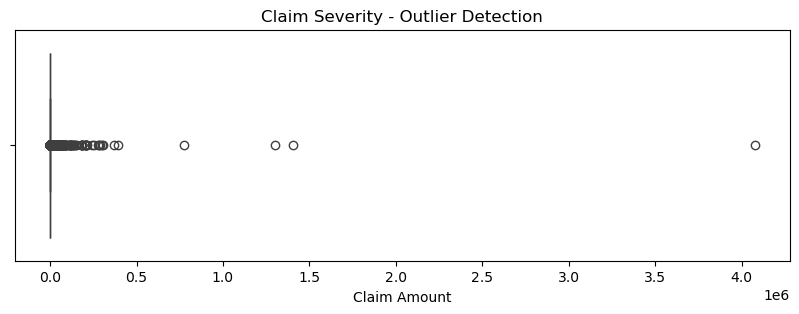

In [21]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=severity_model_data["ClaimAmount"])

plt.title("Claim Severity - Outlier Detection")
plt.xlabel("Claim Amount")
plt.show()

In [22]:
top_claims = severity_model_data.nlargest(
    10, "ClaimAmount"
)[
    ["IDpol", "ClaimAmount", "DrivAge",
     "VehAge", "VehBrand", "Area", "Region"]
]

display(top_claims)

,IDpol,ClaimAmount,DrivAge,VehAge,VehBrand,Area,Region
9756,1120377,4075400.56,19,13,B2,B,Centre
15768,110846,1403057.40,20,13,B1,C,Centre
11637,2141337,1301172.60,18,14,B2,D,Rhone-Alpes
17992,3122016,774411.50,40,7,B11,E,Rhone-Alpes
2869,2008127,390742.27,57,2,B4,D,Rhone-Alpes
3307,3025890,369131.88,36,1,B12,A,Champagne-Ardenne
9999,1117644,307096.42,21,1,B3,C,Bretagne
5521,158309,301635.49,46,3,B1,A,Centre
18627,3075820,287423.00,78,18,B10,E,Provence-Alpes-Cotes-D'Azur
18295,3150210,281897.49,61,4,B3,D,Centre


In [23]:
thresholds = [10000, 50000, 100000, 500000, 1000000]

for threshold in thresholds:
    count = (
        severity_model_data["ClaimAmount"] > threshold
    ).sum()

    print(f"Claims > {threshold:,}: {count}")

Claims > 10,000: 478
Claims > 50,000: 88
Claims > 100,000: 41
Claims > 500,000: 4
Claims > 1,000,000: 3


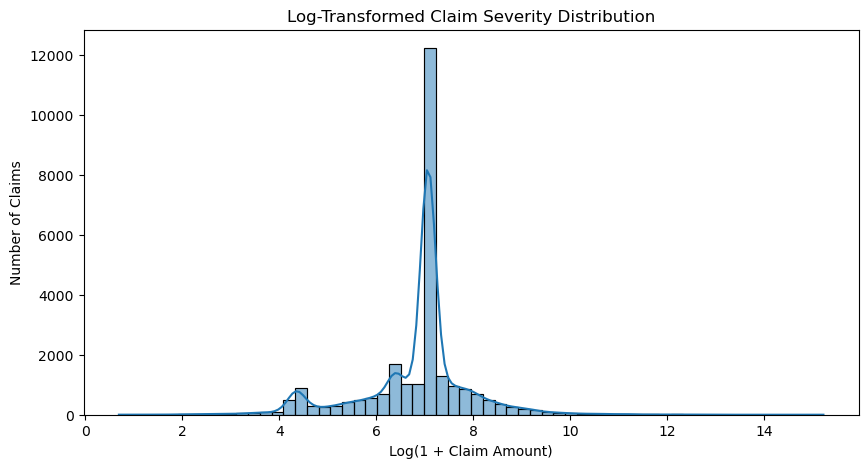

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(severity_model_data["ClaimAmount"]),
    bins=60,
    kde=True
)

plt.title("Log-Transformed Claim Severity Distribution")
plt.xlabel("Log(1 + Claim Amount)")
plt.ylabel("Number of Claims")

plt.show()

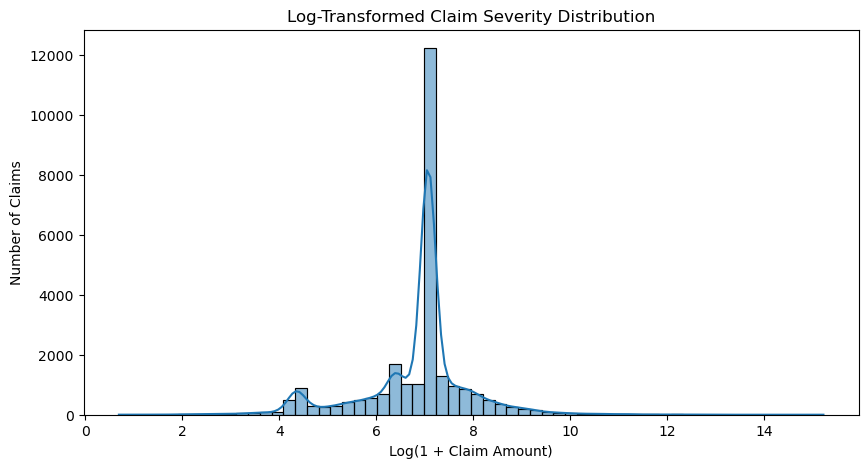

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(severity_model_data["ClaimAmount"]),
    bins=60,
    kde=True
)

plt.title("Log-Transformed Claim Severity Distribution")
plt.xlabel("Log(1 + Claim Amount)")
plt.ylabel("Number of Claims")

plt.show()

In [26]:
log_claims = np.log1p(severity_model_data["ClaimAmount"])

print("Original skewness:",
      severity_model_data["ClaimAmount"].skew())

print("Log transformed skewness:",
      log_claims.skew())

print("\nOriginal values:")
print(severity_model_data["ClaimAmount"].describe())

print("\nLog transformed values:")
print(log_claims.describe())

Original skewness: 109.52986466339235
Log transformed skewness: -0.5274227377201047

Original values:
count    2.644400e+04
mean     2.265513e+03
std      2.937103e+04
min      1.000000e+00
25%      6.859925e+02
50%      1.172000e+03
75%      1.212385e+03
max      4.075401e+06
Name: ClaimAmount, dtype: float64

Log transformed values:
count    26444.000000
mean         6.849403
std          1.124437
min          0.693147
25%          6.532323
50%          7.067320
75%          7.101169
max         15.220480
Name: ClaimAmount, dtype: float64


## 4. Claim Frequency Modeling

In [27]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("Statsmodels version:", sm.__version__)

Statsmodels version: 0.14.5


In [28]:
from sklearn.model_selection import train_test_split

# Select variables
model_data = freq[
    [
        "ClaimNb",
        "Exposure",
        "DrivAge",
        "VehAge",
        "BonusMalus",
        "VehPower",
        "VehBrand",
        "VehGas",
        "Area",
        "Density",
        "Region"
    ]
].copy()

# Check exposure
print("Zero or negative exposure:",
      (model_data["Exposure"] <= 0).sum())

# Split data
train_data, test_data = train_test_split(
    model_data,
    test_size=0.20,
    random_state=42
)

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

Zero or negative exposure: 0
Training shape: (542410, 11)
Testing shape: (135603, 11)


In [29]:
# Poisson GLM Formula
formula = """
ClaimNb ~ DrivAge + VehAge + BonusMalus + Density
+ C(VehPower)
+ C(VehBrand)
+ C(VehGas)
+ C(Area)
+ C(Region)
"""

# Fit Poisson GLM
poisson_model = smf.glm(
    formula=formula,
    data=train_data,
    family=sm.families.Poisson(),
    offset=np.log(train_data["Exposure"])
).fit()

# Display results
print(poisson_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542358
Model Family:                 Poisson   Df Model:                           51
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1447e+05
Date:                Sat, 14 Nov 2026   Deviance:                   1.7354e+05
Time:                        18:43:45   Pearson chi2:                 1.42e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01099
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [30]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_poisson_deviance,
    mean_squared_error
)

# Predict claim counts on test data
y_true = test_data["ClaimNb"]

y_pred = poisson_model.predict(
    test_data,
    offset=np.log(test_data["Exposure"])
)

# Evaluation metrics
mae = mean_absolute_error(y_true, y_pred)

poisson_deviance = mean_poisson_deviance(
    y_true, y_pred
)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

print("===== Poisson Model Evaluation =====")
print("MAE:", round(mae, 4))
print("Poisson Deviance:", round(poisson_deviance, 4))
print("RMSE:", round(rmse, 4))

# Compare observed and predicted claims
print("\nObserved Claims:", y_true.sum())
print("Predicted Claims:", round(y_pred.sum(), 2))

print("\nObserved Frequency:",
      round(y_true.sum() / test_data["Exposure"].sum(), 5))

print("Predicted Frequency:",
      round(y_pred.sum() / test_data["Exposure"].sum(), 5))

===== Poisson Model Evaluation =====
MAE: 0.0988
Poisson Deviance: 0.3212
RMSE: 0.2373

Observed Claims: 7241
Predicted Claims: 7194.82

Observed Frequency: 0.1011
Predicted Frequency: 0.10045


In [ ]:
# Fit Negative Binomial Model (NB2) by maximum likelihood.
# The default starting values let alpha drift to infinity (non-convergence, NaN
# standard errors), so we start from the Poisson coefficients and a
# method-of-moments estimate of alpha, and use Newton-Raphson.
from scipy.optimize import minimize_scalar

mu_start = poisson_model.fittedvalues
y_start = train_data["ClaimNb"]
alpha_start = max(
    np.sum((y_start - mu_start) ** 2 - mu_start) / np.sum(mu_start ** 2),
    1e-3
)

nb_mle = smf.negativebinomial(
    formula=formula,
    data=train_data,
    exposure=train_data["Exposure"]
)

start_params = np.append(poisson_model.params.values, alpha_start)

nb_model = nb_mle.fit(
    start_params=start_params,
    method="newton",
    maxiter=200,
    disp=False
)

if nb_model.mle_retvals["converged"]:
    print("Negative Binomial MLE converged. Alpha =",
          round(float(nb_model.params.iloc[-1]), 4))
    print(nb_model.summary())
else:
    # Fallback: profile likelihood over alpha, with a GLM (IRLS) fit for each alpha
    print("MLE did not converge - using profile likelihood for alpha.")

    def neg_loglike(alpha):
        glm_fit = smf.glm(
            formula=formula,
            data=train_data,
            family=sm.families.NegativeBinomial(alpha=alpha),
            offset=np.log(train_data["Exposure"])
        ).fit(start_params=poisson_model.params.values)
        return -glm_fit.llf

    res = minimize_scalar(
        neg_loglike,
        bounds=(1e-3, 3),
        method="bounded",
        options={"xatol": 1e-3}
    )
    alpha_profile = res.x
    print("Profile-likelihood alpha:", round(alpha_profile, 4))

    nb_model = smf.glm(
        formula=formula,
        data=train_data,
        family=sm.families.NegativeBinomial(alpha=alpha_profile),
        offset=np.log(train_data["Exposure"])
    ).fit()
    print(nb_model.summary())

In [32]:
nb_glm = smf.glm(
    formula=formula,
    data=train_data,
    family=sm.families.NegativeBinomial(alpha=1),
    offset=np.log(train_data["Exposure"])
).fit()

print(nb_glm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542358
Model Family:        NegativeBinomial   Df Model:                           51
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1412e+05
Date:                Sat, 14 Nov 2026   Deviance:                   1.5113e+05
Time:                        18:53:44   Pearson chi2:                 1.37e+06
No. Iterations:                     8   Pseudo R-squ. (CS):            0.01036
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [33]:
nb_glm_pred = nb_glm.predict(
    test_data,
    offset=np.log(test_data["Exposure"])
)

print("===== Negative Binomial GLM Evaluation =====")

print("MAE:",
      round(mean_absolute_error(y_true, nb_glm_pred), 4))

print("Poisson Deviance:",
      round(mean_poisson_deviance(y_true, nb_glm_pred), 4))

print("RMSE:",
      round(np.sqrt(mean_squared_error(y_true, nb_glm_pred)), 4))

print("Observed Claims:", y_true.sum())
print("Predicted Claims:", round(nb_glm_pred.sum(), 2))

===== Negative Binomial GLM Evaluation =====
MAE: 0.0994
Poisson Deviance: 0.3212
RMSE: 0.2374
Observed Claims: 7241
Predicted Claims: 7290.14


In [34]:
# Estimate dispersion from Poisson residuals

pearson_chi2 = poisson_model.pearson_chi2
df_resid = poisson_model.df_resid

dispersion = pearson_chi2 / df_resid

print("Poisson Dispersion:", round(dispersion, 4))
print("Approximate Alpha:", round((dispersion - 1) / np.mean(poisson_model.fittedvalues), 4))

Poisson Dispersion: 2.6192
Approximate Alpha: 30.4309


In [35]:
# Fitted values from Poisson model
mu = poisson_model.fittedvalues

# Actual number of claims
y = train_data["ClaimNb"]

# Method of Moments approximation for NB2 alpha
numerator = np.sum((y - mu)**2 - mu)
denominator = np.sum(mu**2)

alpha_hat = max(numerator / denominator, 0)

print("Estimated Alpha:", round(alpha_hat, 4))

Estimated Alpha: 0.8432


In [36]:
nb_glm_estimated = smf.glm(
    formula=formula,
    data=train_data,
    family=sm.families.NegativeBinomial(alpha=alpha_hat),
    offset=np.log(train_data["Exposure"])
).fit()

print(nb_glm_estimated.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542358
Model Family:        NegativeBinomial   Df Model:                           51
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1412e+05
Date:                Sat, 14 Nov 2026   Deviance:                   1.5388e+05
Time:                        19:01:40   Pearson chi2:                 1.38e+06
No. Iterations:                     8   Pseudo R-squ. (CS):            0.01045
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [37]:
nb_est_pred = nb_glm_estimated.predict(
    test_data,
    offset=np.log(test_data["Exposure"])
)

print("===== Negative Binomial - Estimated Alpha =====")

print("MAE:",
      round(mean_absolute_error(y_true, nb_est_pred), 4))

print("Poisson Deviance:",
      round(mean_poisson_deviance(y_true, nb_est_pred), 4))

print("RMSE:",
      round(np.sqrt(mean_squared_error(y_true, nb_est_pred)), 4))

print("Observed Claims:", y_true.sum())
print("Predicted Claims:", round(nb_est_pred.sum(), 2))

===== Negative Binomial - Estimated Alpha =====
MAE: 0.0993
Poisson Deviance: 0.3212
RMSE: 0.2374
Observed Claims: 7241
Predicted Claims: 7275.7


In [38]:
model_comparison = pd.DataFrame({
    "Model": [
        "Poisson",
        "Negative Binomial alpha=1",
        "Negative Binomial alpha=0.8432"
    ],
    "MAE": [0.0988, 0.0994, 0.0993],
    "Poisson_Deviance": [0.3212, 0.3212, 0.3212],
    "RMSE": [0.2373, 0.2374, 0.2374],
    "Predicted_Claims": [7194.82, 7290.14, 7275.70]
})

model_comparison.to_csv(
    "Insurance_Claims_Pricing/Frequency_Model_Comparison.csv",
    index=False
)

model_comparison

,Model,MAE,Poisson_Deviance,RMSE,Predicted_Claims
0,Poisson,0.0988,0.3212,0.2373,7194.82
1,Negative Binomial alpha=1,0.0994,0.3212,0.2374,7290.14
2,Negative Binomial alpha=0.8432,0.0993,0.3212,0.2374,7275.70


In [39]:
calibration_data = test_data.copy()

calibration_data["Actual_Claims"] = y_true
calibration_data["Predicted_Claims"] = poisson_model.predict(
    test_data,
    offset=np.log(test_data["Exposure"])
)

calibration_data["Risk_Decile"] = pd.qcut(
    calibration_data["Predicted_Claims"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

calibration = calibration_data.groupby("Risk_Decile").agg(
    Policies=("ClaimNb", "count"),
    Actual_Claims=("Actual_Claims", "sum"),
    Predicted_Claims=("Predicted_Claims", "sum"),
    Actual_Frequency=("Actual_Claims", "mean"),
    Predicted_Frequency=("Predicted_Claims", "mean")
)

calibration["Prediction_Ratio"] = (
    calibration["Predicted_Claims"] /
    calibration["Actual_Claims"]
)

calibration.round(4)

,Policies,Actual_Claims,Predicted_Claims,Actual_Frequency,Predicted_Frequency,Prediction_Ratio
Risk_Decile,,,,,,
1,13561,318,47.9386,0.0234,0.0035,0.1508
2,13560,352,121.7808,0.0260,0.0090,0.3460
3,13560,489,233.3358,0.0361,0.0172,0.4772
4,13560,582,387.5730,0.0429,0.0286,0.6659
5,13561,612,561.1951,0.0451,0.0414,0.9170
6,13560,689,728.2494,0.0508,0.0537,1.0570
7,13560,773,884.3780,0.0570,0.0652,1.1441
8,13560,875,1048.1847,0.0645,0.0773,1.1979
9,13560,1003,1256.9609,0.0740,0.0927,1.2532


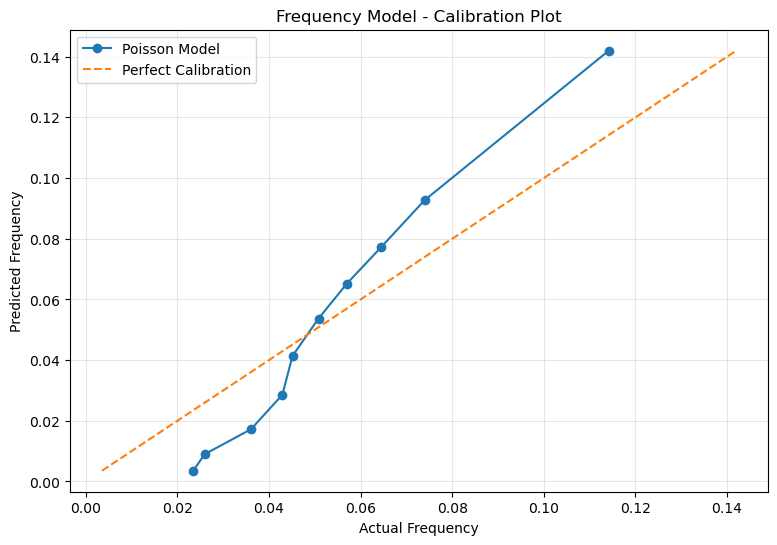

In [40]:
plt.figure(figsize=(9, 6))

plt.plot(
    calibration["Actual_Frequency"],
    calibration["Predicted_Frequency"],
    marker="o",
    label="Poisson Model"
)

min_val = min(
    calibration["Actual_Frequency"].min(),
    calibration["Predicted_Frequency"].min()
)

max_val = max(
    calibration["Actual_Frequency"].max(),
    calibration["Predicted_Frequency"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Actual Frequency")
plt.ylabel("Predicted Frequency")
plt.title("Frequency Model - Calibration Plot")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [41]:
calibration.to_csv(
    "Insurance_Claims_Pricing/Frequency_Calibration.csv"
)

## 5. Claim Severity Modeling

In [42]:
from sklearn.model_selection import GroupShuffleSplit

# Verify positive claim amounts
print("Non-positive amounts:",
      (severity_model_data["ClaimAmount"] <= 0).sum())

# Define variables
severity_formula = """
ClaimAmount ~ DrivAge + VehAge + BonusMalus + Density
+ C(VehPower)
+ C(VehBrand)
+ C(VehGas)
+ C(Area)
+ C(Region)
"""

# Split by policy ID to avoid data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        severity_model_data,
        groups=severity_model_data["IDpol"]
    )
)

severity_train = severity_model_data.iloc[train_idx].copy()
severity_test = severity_model_data.iloc[test_idx].copy()

print("Training shape:", severity_train.shape)
print("Testing shape:", severity_test.shape)

print("Train policies:",
      severity_train["IDpol"].nunique())

print("Test policies:",
      severity_test["IDpol"].nunique())

print("Common policies:",
      len(set(severity_train["IDpol"]) &
          set(severity_test["IDpol"])))

Non-positive amounts: 0
Training shape: (21177, 16)
Testing shape: (5267, 16)
Train policies: 19955
Test policies: 4989
Common policies: 0


In [43]:
gamma_model = smf.glm(
    formula=severity_formula,
    data=severity_train,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit()

print(gamma_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:            ClaimAmount   No. Observations:                21177
Model:                            GLM   Df Residuals:                    21125
Model Family:                   Gamma   Df Model:                           51
Link Function:                    Log   Scale:                          35.577
Method:                          IRLS   Log-Likelihood:            -2.2350e+05
Date:                Sat, 14 Nov 2026   Deviance:                       34380.
Time:                        19:37:29   Pearson chi2:                 7.52e+05
No. Iterations:                   100   Pseudo R-squ. (CS):           0.004484
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [44]:
print("Model converged:", gamma_model.converged)

print("Iterations:",
      gamma_model.fit_history.get("iteration"))

print("Training observations:",
      gamma_model.nobs)

print("Minimum prediction:",
      gamma_model.predict(severity_train).min())

print("Maximum prediction:",
      gamma_model.predict(severity_train).max())

Model converged: False
Iterations: 100
Training observations: 21177
Minimum prediction: 679.5737402286846
Maximum prediction: 12992.9856711509


In [45]:
# Check numerical variables
numeric_cols = [
    "ClaimAmount", "DrivAge", "VehAge",
    "BonusMalus", "Density", "VehPower"
]

print("Missing values:")
print(severity_train[numeric_cols].isnull().sum())

print("\nDescriptive statistics:")
display(severity_train[numeric_cols].describe().T)

print("\nExtreme ClaimAmount values:")
display(
    severity_train.nlargest(10, "ClaimAmount")[
        ["IDpol", "ClaimAmount"]
    ]
)

Missing values:
ClaimAmount    0
DrivAge        0
VehAge         0
BonusMalus     0
Density        0
VehPower       0
dtype: int64

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
ClaimAmount,21177.0,2294.246512,31166.394308,1.0,678.84,1172.0,1218.28,4075400.56
DrivAge,21177.0,45.082259,14.695192,18.0,34.00,45.0,54.00,99.00
VehAge,21177.0,7.372385,5.187345,0.0,3.00,7.0,11.00,99.00
BonusMalus,21177.0,65.355197,20.316905,50.0,50.00,55.0,76.00,228.00
Density,21177.0,2024.289843,4146.504489,2.0,116.00,540.0,2252.00,27000.00
VehPower,21177.0,6.457241,2.016923,4.0,5.00,6.0,7.00,15.00



Extreme ClaimAmount values:


,IDpol,ClaimAmount
9756,1120377,4075400.56
11637,2141337,1301172.60
17992,3122016,774411.50
2869,2008127,390742.27
3307,3025890,369131.88
9999,1117644,307096.42
5521,158309,301635.49
18627,3075820,287423.00
18295,3150210,281897.49
20347,4169019,276643.00


In [46]:
# Copy datasets to preserve original data
severity_train_scaled = severity_train.copy()
severity_test_scaled = severity_test.copy()

# Numerical predictors
scale_cols = ["DrivAge", "VehAge", "BonusMalus", "Density"]

# Standardization using training data only
for col in scale_cols:
    mean_value = severity_train[col].mean()
    std_value = severity_train[col].std()

    severity_train_scaled[col + "_scaled"] = (
        severity_train[col] - mean_value
    ) / std_value

    severity_test_scaled[col + "_scaled"] = (
        severity_test[col] - mean_value
    ) / std_value

# New formula
severity_formula_scaled = """
ClaimAmount ~ DrivAge_scaled + VehAge_scaled
+ BonusMalus_scaled + Density_scaled
+ C(VehPower)
+ C(VehBrand)
+ C(VehGas)
+ C(Area)
+ C(Region)
"""

# Fit Gamma GLM
gamma_model_scaled = smf.glm(
    formula=severity_formula_scaled,
    data=severity_train_scaled,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit(maxiter=500, tol=1e-8)

print("Model converged:", gamma_model_scaled.converged)
print("Iterations:", gamma_model_scaled.fit_history["iteration"])
print("Scale:", gamma_model_scaled.scale)
print(gamma_model_scaled.summary())

Model converged: True
Iterations: 128
Scale: 35.576939964499715
                 Generalized Linear Model Regression Results                  
Dep. Variable:            ClaimAmount   No. Observations:                21177
Model:                            GLM   Df Residuals:                    21125
Model Family:                   Gamma   Df Model:                           51
Link Function:                    Log   Scale:                          35.577
Method:                          IRLS   Log-Likelihood:            -2.2350e+05
Date:                Sat, 14 Nov 2026   Deviance:                       34380.
Time:                        19:41:41   Pearson chi2:                 7.52e+05
No. Iterations:                   128   Pseudo R-squ. (CS):           0.004484
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------

In [47]:
print("VehAge = 99:", (severity_train["VehAge"] == 99).sum())

VehAge = 99: 1


In [48]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_gamma_deviance
)

# Actual and predicted claim amounts
y_test_severity = severity_test_scaled["ClaimAmount"]

y_pred_severity = gamma_model_scaled.predict(
    severity_test_scaled
)

# Baseline: predict the training mean for every claim
baseline_pred = np.full(
    len(y_test_severity),
    severity_train_scaled["ClaimAmount"].mean()
)

# Evaluation function
def evaluate_severity(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Gamma Deviance": mean_gamma_deviance(y_true, y_pred),
        "Mean Prediction": np.mean(y_pred)
    }

severity_results = pd.DataFrame([
    evaluate_severity(
        y_test_severity,
        y_pred_severity,
        "Gamma GLM"
    ),
    evaluate_severity(
        y_test_severity,
        baseline_pred,
        "Mean Baseline"
    )
])

display(severity_results)

print("Actual mean severity:", y_test_severity.mean())
print("Actual median severity:", y_test_severity.median())
print("Predicted minimum:", y_pred_severity.min())
print("Predicted maximum:", y_pred_severity.max())

,Model,MAE,RMSE,Gamma Deviance,Mean Prediction
0,Gamma GLM,2151.146037,20638.817119,1.663162,2222.973349
1,Mean Baseline,2181.522387,20632.167319,1.655565,2294.246512


Actual mean severity: 2149.9825555344596
Actual median severity: 1172.0
Predicted minimum: 861.6571993830048
Predicted maximum: 9280.241884336932


In [49]:
# Create evaluation dataframe
severity_calibration = pd.DataFrame({
    "Actual_Severity": y_test_severity,
    "Predicted_Severity": y_pred_severity
})

# Divide predictions into 10 groups
severity_calibration["Risk_Decile"] = pd.qcut(
    severity_calibration["Predicted_Severity"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

# Compare actual and predicted severity
severity_deciles = severity_calibration.groupby(
    "Risk_Decile"
).agg(
    Number_of_Claims=("Actual_Severity", "count"),
    Actual_Mean=("Actual_Severity", "mean"),
    Predicted_Mean=("Predicted_Severity", "mean"),
    Actual_Median=("Actual_Severity", "median"),
    Actual_Total=("Actual_Severity", "sum"),
    Predicted_Total=("Predicted_Severity", "sum")
)

severity_deciles["Prediction_Ratio"] = (
    severity_deciles["Predicted_Total"] /
    severity_deciles["Actual_Total"]
)

display(severity_deciles.round(3))

,Number_of_Claims,Actual_Mean,Predicted_Mean,Actual_Median,Actual_Total,Predicted_Total,Prediction_Ratio
Risk_Decile,,,,,,,
1,527,1589.013,1308.494,1172.000,837409.97,689576.392,0.823
2,527,1744.407,1568.897,1172.000,919302.39,826808.564,0.899
3,526,2325.573,1728.552,1172.000,1223251.40,909218.222,0.743
4,527,2095.469,1868.311,1172.000,1104311.91,984600.059,0.892
5,527,2069.679,2005.866,1172.000,1090720.74,1057091.178,0.969
6,526,1508.448,2145.786,1172.000,793443.77,1128683.412,1.423
7,527,1580.950,2305.427,1172.000,833160.56,1214960.057,1.458
8,526,2214.908,2507.722,1157.025,1165041.78,1319061.793,1.132
9,527,4118.048,2834.501,1128.120,2170211.42,1493782.051,0.688


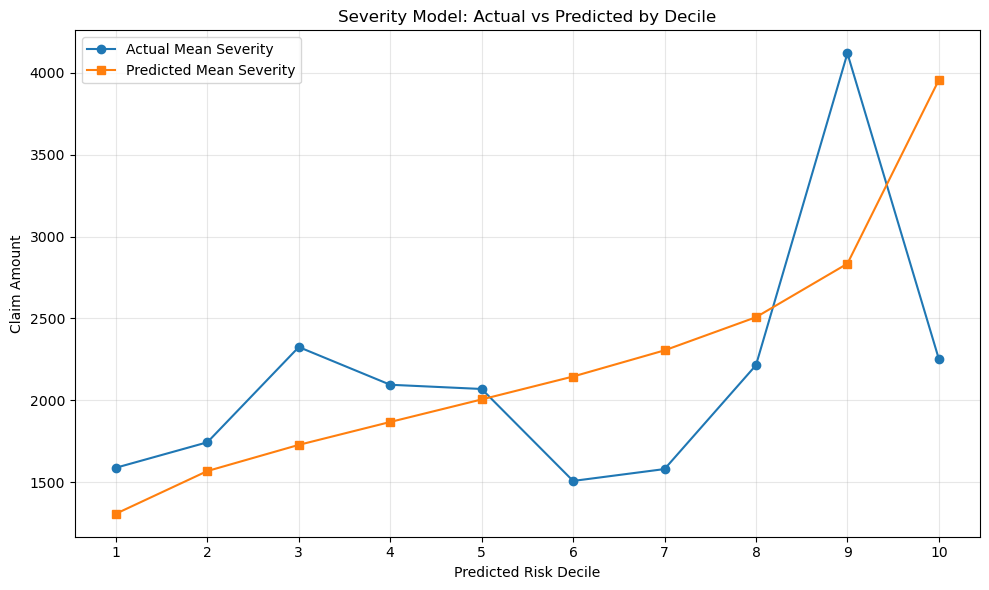

In [50]:
plt.figure(figsize=(10, 6))

plt.plot(
    severity_deciles.index,
    severity_deciles["Actual_Mean"],
    marker="o",
    label="Actual Mean Severity"
)

plt.plot(
    severity_deciles.index,
    severity_deciles["Predicted_Mean"],
    marker="s",
    label="Predicted Mean Severity"
)

plt.xlabel("Predicted Risk Decile")
plt.ylabel("Claim Amount")
plt.title("Severity Model: Actual vs Predicted by Decile")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Features
numeric_features = [
    "DrivAge", "VehAge", "BonusMalus", "Density"
]

categorical_features = [
    "VehPower", "VehBrand", "VehGas", "Area", "Region"
]

features = numeric_features + categorical_features

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Lognormal model
lognormal_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train using log of ClaimAmount
lognormal_model.fit(
    severity_train_scaled[features],
    np.log(severity_train_scaled["ClaimAmount"])
)

print("Lognormal model trained successfully!")

Lognormal model trained successfully!


In [52]:
# Predict log severity
log_predictions = lognormal_model.predict(
    severity_test_scaled[features]
)

# Convert back to original scale
lognormal_predictions = np.exp(log_predictions)

# Evaluate
lognormal_results = evaluate_severity(
    y_test_severity,
    lognormal_predictions,
    "Lognormal Regression"
)

display(pd.DataFrame([lognormal_results]))

,Model,MAE,RMSE,Gamma Deviance,Mean Prediction
0,Lognormal Regression,1527.907894,20664.73452,2.524423,948.398929


In [53]:
# Predictions on training data (log scale)
log_train_pred = lognormal_model.predict(
    severity_train_scaled[features]
)

# Actual values on log scale
log_train_actual = np.log(
    severity_train_scaled["ClaimAmount"]
)

# Duan's smearing factor
smearing_factor = np.mean(
    np.exp(log_train_actual - log_train_pred)
)

print("Smearing factor:", smearing_factor)

# Correct test predictions
lognormal_corrected = (
    lognormal_predictions * smearing_factor
)

# Evaluate corrected model
corrected_results = evaluate_severity(
    y_test_severity,
    lognormal_corrected,
    "Lognormal Corrected"
)

display(pd.DataFrame([corrected_results]))

print("Actual mean:", y_test_severity.mean())
print("Corrected predicted mean:", lognormal_corrected.mean())

Smearing factor: 2.4443967672847093


,Model,MAE,RMSE,Gamma Deviance,Mean Prediction
0,Lognormal Corrected,2204.758548,20629.753843,1.632995,2318.263276


Actual mean: 2149.9825555344596
Corrected predicted mean: 2318.263276272816


In [54]:
# Create corrected Lognormal calibration data
lognormal_calibration = pd.DataFrame({
    "Actual_Severity": y_test_severity,
    "Predicted_Severity": lognormal_corrected
})

# Divide predictions into 10 groups
lognormal_calibration["Risk_Decile"] = pd.qcut(
    lognormal_calibration["Predicted_Severity"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

# Calibration table
lognormal_deciles = lognormal_calibration.groupby(
    "Risk_Decile"
).agg(
    Number_of_Claims=("Actual_Severity", "count"),
    Actual_Mean=("Actual_Severity", "mean"),
    Predicted_Mean=("Predicted_Severity", "mean"),
    Actual_Total=("Actual_Severity", "sum"),
    Predicted_Total=("Predicted_Severity", "sum")
)

lognormal_deciles["Prediction_Ratio"] = (
    lognormal_deciles["Predicted_Total"] /
    lognormal_deciles["Actual_Total"]
)

display(lognormal_deciles.round(3))

,Number_of_Claims,Actual_Mean,Predicted_Mean,Actual_Total,Predicted_Total,Prediction_Ratio
Risk_Decile,,,,,,
1,527,1331.714,1836.828,701813.27,968008.355,1.379
2,527,1427.715,1973.175,752405.55,1039863.073,1.382
3,526,1749.028,2058.515,919988.70,1082778.736,1.177
4,533,1861.060,2132.681,991945.07,1136718.749,1.146
5,521,4470.183,2205.406,2328965.23,1149016.380,0.493
6,526,1788.642,2286.261,940825.82,1202573.344,1.278
7,527,1930.686,2379.186,1017471.34,1253831.224,1.232
8,526,1795.869,2503.068,944626.85,1316613.667,1.394
9,527,2088.359,2684.509,1100565.15,1414736.117,1.285


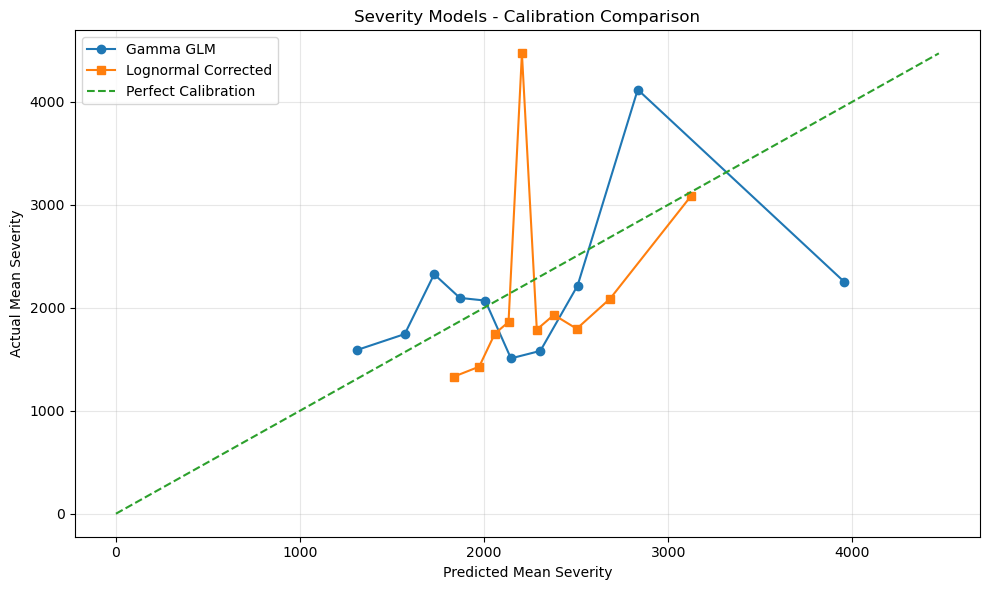

In [55]:
plt.figure(figsize=(10, 6))

plt.plot(
    severity_deciles["Predicted_Mean"],
    severity_deciles["Actual_Mean"],
    marker="o",
    label="Gamma GLM"
)

plt.plot(
    lognormal_deciles["Predicted_Mean"],
    lognormal_deciles["Actual_Mean"],
    marker="s",
    label="Lognormal Corrected"
)

# Ideal calibration line
max_value = max(
    severity_deciles["Predicted_Mean"].max(),
    severity_deciles["Actual_Mean"].max(),
    lognormal_deciles["Predicted_Mean"].max(),
    lognormal_deciles["Actual_Mean"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Predicted Mean Severity")
plt.ylabel("Actual Mean Severity")
plt.title("Severity Models - Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
# Compare prediction errors for both models

severity_errors = pd.DataFrame({
    "Actual": y_test_severity,
    "Gamma_Predicted": y_pred_severity,
    "Lognormal_Predicted": lognormal_corrected
})

severity_errors["Gamma_Error"] = (
    severity_errors["Actual"] -
    severity_errors["Gamma_Predicted"]
)

severity_errors["Lognormal_Error"] = (
    severity_errors["Actual"] -
    severity_errors["Lognormal_Predicted"]
)

display(
    severity_errors[
        [
            "Actual",
            "Gamma_Error",
            "Lognormal_Error"
        ]
    ].describe().round(2)
)

,Actual,Gamma_Error,Lognormal_Error
count,5267.00,5267.00,5267.00
mean,2149.98,-72.99,-168.28
std,20633.62,20640.65,20631.03
min,1.82,-8174.45,-4123.46
25%,706.59,-1604.44,-1667.40
50%,1172.00,-984.31,-1180.21
75%,1204.00,-426.14,-806.61
max,1403057.40,1400399.38,1400857.74


In [57]:
# Identify the largest claims in the test set

severity_errors["Claim_Percentile"] = (
    severity_errors["Actual"].rank(pct=True) * 100
)

# Separate the top 1% of claims
top_1_percent = severity_errors[
    severity_errors["Claim_Percentile"] >= 99
]

# Compare errors for all claims vs top 1%
print("Total test claims:", len(severity_errors))
print("Top 1% claims:", len(top_1_percent))

print("\nOverall MAE:")
print("Gamma:", mean_absolute_error(
    severity_errors["Actual"],
    severity_errors["Gamma_Predicted"]
))
print("Lognormal:", mean_absolute_error(
    severity_errors["Actual"],
    severity_errors["Lognormal_Predicted"]
))

print("\nTop 1% MAE:")
print("Gamma:", mean_absolute_error(
    top_1_percent["Actual"],
    top_1_percent["Gamma_Predicted"]
))
print("Lognormal:", mean_absolute_error(
    top_1_percent["Actual"],
    top_1_percent["Lognormal_Predicted"]
))

Total test claims: 5267
Top 1% claims: 53

Overall MAE:
Gamma: 2151.1460368014527
Lognormal: 2204.758547989587

Top 1% MAE:
Gamma: 74484.83421743533
Lognormal: 74330.7722536851


In [58]:
# Separate regular claims from extreme claims

regular_claims = severity_errors[
    severity_errors["Claim_Percentile"] < 99
]

def compare_errors(data, group_name):
    return {
        "Group": group_name,
        "Number_of_Claims": len(data),
        "Gamma_MAE": mean_absolute_error(
            data["Actual"], data["Gamma_Predicted"]
        ),
        "Lognormal_MAE": mean_absolute_error(
            data["Actual"], data["Lognormal_Predicted"]
        ),
        "Gamma_RMSE": np.sqrt(mean_squared_error(
            data["Actual"], data["Gamma_Predicted"]
        )),
        "Lognormal_RMSE": np.sqrt(mean_squared_error(
            data["Actual"], data["Lognormal_Predicted"]
        ))
    }

comparison_groups = pd.DataFrame([
    compare_errors(regular_claims, "Regular 99%"),
    compare_errors(top_1_percent, "Extreme Top 1%")
])

display(comparison_groups.round(2))

,Group,Number_of_Claims,Gamma_MAE,Lognormal_MAE,Gamma_RMSE,Lognormal_RMSE
0,Regular 99%,5214,1415.88,1471.60,1891.6,1807.74
1,Extreme Top 1%,53,74484.83,74330.77,204887.4,204871.17


In [59]:
# Inspect the 10 largest claims

largest_claims = severity_errors.nlargest(
    10, "Actual"
).copy()

largest_claims["Gamma_Absolute_Error"] = (
    largest_claims["Actual"] -
    largest_claims["Gamma_Predicted"]
).abs()

largest_claims["Lognormal_Absolute_Error"] = (
    largest_claims["Actual"] -
    largest_claims["Lognormal_Predicted"]
).abs()

display(
    largest_claims[
        [
            "Actual",
            "Gamma_Predicted",
            "Lognormal_Predicted",
            "Gamma_Absolute_Error",
            "Lognormal_Absolute_Error"
        ]
    ].round(2)
)

,Actual,Gamma_Predicted,Lognormal_Predicted,Gamma_Absolute_Error,Lognormal_Absolute_Error
15768,1403057.40,2658.02,2199.66,1400399.38,1400857.74
6837,205432.05,1889.46,2910.61,203542.59,202521.44
12437,205132.00,3828.10,2990.37,201303.90,202141.63
1088,200885.00,1999.69,3733.91,198885.31,197151.09
12992,182878.18,1685.06,2607.65,181193.12,180270.53
5877,137169.81,2454.37,2397.08,134715.44,134772.73
827,125847.05,2431.64,2913.83,123415.41,122933.22
8108,121959.21,1537.66,2454.53,120421.55,119504.68
3270,114759.95,1754.58,2165.36,113005.37,112594.59
12149,92149.00,3780.78,2230.24,88368.22,89918.76


In [60]:
# Calculate prediction-to-actual ratios for the 10 largest claims

largest_claims["Gamma_Ratio"] = (
    largest_claims["Gamma_Predicted"] /
    largest_claims["Actual"]
)

largest_claims["Lognormal_Ratio"] = (
    largest_claims["Lognormal_Predicted"] /
    largest_claims["Actual"]
)

display(
    largest_claims[
        [
            "Actual",
            "Gamma_Predicted",
            "Gamma_Ratio",
            "Lognormal_Predicted",
            "Lognormal_Ratio"
        ]
    ].round(4)
)

,Actual,Gamma_Predicted,Gamma_Ratio,Lognormal_Predicted,Lognormal_Ratio
15768,1403057.40,2658.0229,0.0019,2199.6593,0.0016
6837,205432.05,1889.4613,0.0092,2910.6135,0.0142
12437,205132.00,3828.0991,0.0187,2990.3650,0.0146
1088,200885.00,1999.6857,0.0100,3733.9093,0.0186
12992,182878.18,1685.0650,0.0092,2607.6476,0.0143
5877,137169.81,2454.3700,0.0179,2397.0824,0.0175
827,125847.05,2431.6444,0.0193,2913.8279,0.0232
8108,121959.21,1537.6598,0.0126,2454.5262,0.0201
3270,114759.95,1754.5816,0.0153,2165.3603,0.0189
12149,92149.00,3780.7751,0.0410,2230.2358,0.0242


In [62]:
# Duan Smearing Correction for Gradient Boosting

boost_train_log_pred = boost_model.predict(
    severity_train_scaled[features]
)

boost_train_log_actual = np.log(
    severity_train_scaled["ClaimAmount"]
)

boost_smearing_factor = np.mean(
    np.exp(boost_train_log_actual - boost_train_log_pred)
)

boost_corrected_predictions = (
    boost_predictions * boost_smearing_factor
)

print("Smearing Factor:", boost_smearing_factor)

print("\nCorrected Gradient Boosting:")
print("MAE:", mean_absolute_error(
    y_test_severity, boost_corrected_predictions
))

print("RMSE:", np.sqrt(mean_squared_error(
    y_test_severity, boost_corrected_predictions
)))

print("Mean Prediction:", boost_corrected_predictions.mean())
print("Actual Mean:", y_test_severity.mean())

Smearing Factor: 2.343408539028649

Corrected Gradient Boosting:
MAE: 2128.08983889496
RMSE: 20627.0179355736
Mean Prediction: 2217.7789125755808
Actual Mean: 2149.9825555344596


In [65]:
boost_calibration = pd.DataFrame({
    "Actual_Severity": y_test_severity,
    "Predicted_Severity": boost_corrected_predictions
})

boost_calibration["Risk_Decile"] = pd.qcut(
    boost_calibration["Predicted_Severity"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

boost_deciles = boost_calibration.groupby(
    "Risk_Decile"
).agg(
    Number_of_Claims=("Actual_Severity", "count"),
    Actual_Mean=("Actual_Severity", "mean"),
    Predicted_Mean=("Predicted_Severity", "mean"),
    Actual_Total=("Actual_Severity", "sum"),
    Predicted_Total=("Predicted_Severity", "sum")
)

boost_deciles["Prediction_Ratio"] = (
    boost_deciles["Predicted_Total"] /
    boost_deciles["Actual_Total"]
)

display(boost_deciles.round(3))

,Number_of_Claims,Actual_Mean,Predicted_Mean,Actual_Total,Predicted_Total,Prediction_Ratio
Risk_Decile,,,,,,
1,527,1324.838,1703.549,698189.56,897770.557,1.286
2,528,1558.325,1944.858,822795.40,1026884.959,1.248
3,525,1361.964,2009.630,715030.98,1055055.778,1.476
4,527,1786.745,2062.363,941614.73,1086865.511,1.154
5,527,1926.861,2134.412,1015455.95,1124835.035,1.108
6,526,2173.179,2263.065,1143092.02,1190372.137,1.041
7,531,5106.427,2380.795,2711512.83,1264202.221,0.466
8,522,2073.794,2464.216,1082520.41,1286320.784,1.188
9,535,1967.789,2539.607,1052767.26,1358689.692,1.291


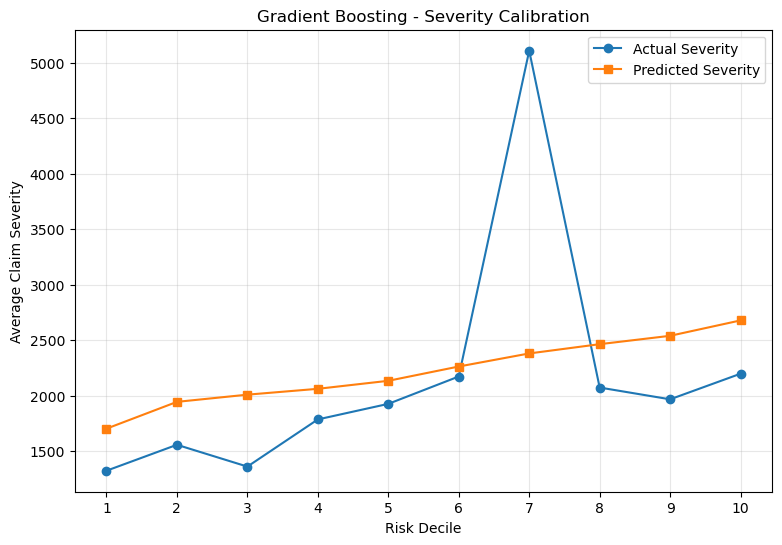

In [66]:
plt.figure(figsize=(9, 6))

plt.plot(
    boost_deciles.index,
    boost_deciles["Actual_Mean"],
    marker="o",
    label="Actual Severity"
)

plt.plot(
    boost_deciles.index,
    boost_deciles["Predicted_Mean"],
    marker="s",
    label="Predicted Severity"
)

plt.xlabel("Risk Decile")
plt.ylabel("Average Claim Severity")
plt.title("Gradient Boosting - Severity Calibration")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [67]:
severity_final_comparison = pd.DataFrame([
    {
        "Model": "Gamma GLM",
        "MAE": mean_absolute_error(
            y_test_severity, y_pred_severity
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test_severity, y_pred_severity
        )),
        "Mean_Prediction": np.mean(y_pred_severity)
    },
    {
        "Model": "Lognormal Corrected",
        "MAE": mean_absolute_error(
            y_test_severity, lognormal_corrected
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test_severity, lognormal_corrected
        )),
        "Mean_Prediction": np.mean(lognormal_corrected)
    },
    {
        "Model": "Gradient Boosting Corrected",
        "MAE": mean_absolute_error(
            y_test_severity, boost_corrected_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test_severity, boost_corrected_predictions
        )),
        "Mean_Prediction": np.mean(boost_corrected_predictions)
    }
])

display(severity_final_comparison.round(3))

severity_final_comparison.to_csv(
    "Insurance_Claims_Pricing/Severity_Model_Comparison.csv",
    index=False
)

,Model,MAE,RMSE,Mean_Prediction
0,Gamma GLM,2151.146,20638.817,2222.973
1,Lognormal Corrected,2204.759,20629.754,2318.263
2,Gradient Boosting Corrected,2128.090,20627.018,2217.779


## 6. Data Integration and Model Validation

In [68]:
print("Frequency dataset:", freq.shape)
print("Severity matched dataset:", severity_model_data.shape)

print("\nTotal claims in frequency:")
print(freq["ClaimNb"].sum())

print("\nMatched severity claims:")
print(len(severity_model_data))

print("\nUnique policies in frequency:")
print(freq["IDpol"].nunique())

print("\nUnique policies in severity:")
print(severity_model_data["IDpol"].nunique())

Frequency dataset: (678013, 12)
Severity matched dataset: (26444, 16)

Total claims in frequency:
36102

Matched severity claims:
26444

Unique policies in frequency:
678013

Unique policies in severity:
24944


In [69]:
# Total observed severity amount
total_severity = severity_model_data["ClaimAmount"].sum()

# Total exposure
total_exposure = freq["Exposure"].sum()

# Observed matched severity cost per exposure
observed_severity_cost = total_severity / total_exposure

# Average matched claim severity
average_severity = severity_model_data["ClaimAmount"].mean()

print("Total Severity Amount:", round(total_severity, 2))
print("Total Exposure:", round(total_exposure, 2))
print("Average Matched Severity:", round(average_severity, 2))
print("Observed Matched Severity Cost per Exposure:",
      round(observed_severity_cost, 2))

Total Severity Amount: 59909216.5
Total Exposure: 358499.45
Average Matched Severity: 2265.51
Observed Matched Severity Cost per Exposure: 167.11


In [70]:
required_objects = [
    "poisson_model",
    "gamma_model_scaled",
    "severity_gb_model",
    "smearing_factor_gb",
    "test_data",
    "severity_test"
]

for obj in required_objects:
    print(obj, ":", obj in globals())

poisson_model : True
gamma_model_scaled : True
severity_gb_model : False
smearing_factor_gb : False
test_data : True
severity_test : True


In [71]:
required_objects = [
    "severity_train",
    "severity_test",
    "severity_train_scaled",
    "severity_test_scaled",
    "test_data",
    "gamma_model_scaled",
    "poisson_model"
]

for obj in required_objects:
    print(f"{obj}: {obj in globals()}")

severity_train: True
severity_test: True
severity_train_scaled: True
severity_test_scaled: True
test_data: True
gamma_model_scaled: True
poisson_model: True


### 6.1 Frequency and Severity Predictions

In [72]:
# Predict claim counts using the Poisson model
test_data = test_data.copy()

test_data["Predicted_ClaimNb"] = poisson_model.predict(
    test_data,
    offset=np.log(test_data["Exposure"])
)

# Convert predicted claim counts into annual frequency
test_data["Predicted_Frequency"] = (
    test_data["Predicted_ClaimNb"] / test_data["Exposure"]
)

print("Observed total claims:",
      test_data["ClaimNb"].sum())

print("Predicted total claims:",
      round(test_data["Predicted_ClaimNb"].sum(), 2))

print("Observed claim frequency:",
      round(test_data["ClaimNb"].sum() / test_data["Exposure"].sum(), 5))

print("Predicted claim frequency:",
      round(test_data["Predicted_ClaimNb"].sum() / test_data["Exposure"].sum(), 5))

Observed total claims: 7241
Predicted total claims: 7194.82
Observed claim frequency: 0.1011
Predicted claim frequency: 0.10045


In [73]:
# Predict claim severity using Gamma GLM
severity_test_scaled = severity_test_scaled.copy()

severity_test_scaled["Gamma_Predicted_Severity"] = (
    gamma_model_scaled.predict(severity_test_scaled)
)

print("Observed Mean Severity:",
      round(severity_test_scaled["ClaimAmount"].mean(), 2))

print("Predicted Mean Severity:",
      round(severity_test_scaled["Gamma_Predicted_Severity"].mean(), 2))

print("Observed Total Severity:",
      round(severity_test_scaled["ClaimAmount"].sum(), 2))

print("Predicted Total Severity:",
      round(severity_test_scaled["Gamma_Predicted_Severity"].sum(), 2))

Observed Mean Severity: 2149.98
Predicted Mean Severity: 2222.97
Observed Total Severity: 11323958.12
Predicted Total Severity: 11708400.63


In [74]:
# Aggregate frequency and severity indicators

observed_frequency = (
    test_data["ClaimNb"].sum() / test_data["Exposure"].sum()
)

predicted_frequency = (
    test_data["Predicted_ClaimNb"].sum() / test_data["Exposure"].sum()
)

observed_severity = severity_test_scaled["ClaimAmount"].mean()

predicted_severity = (
    severity_test_scaled["Gamma_Predicted_Severity"].mean()
)

observed_pp_proxy = observed_frequency * observed_severity
predicted_pp_proxy = predicted_frequency * predicted_severity

print("Observed Pure Premium Proxy:",
      round(observed_pp_proxy, 2))

print("Predicted Pure Premium Proxy:",
      round(predicted_pp_proxy, 2))

print("Relative Difference (%):",
      round(
          (predicted_pp_proxy / observed_pp_proxy - 1) * 100,
          2
      ))

Observed Pure Premium Proxy: 217.36
Predicted Pure Premium Proxy: 223.3
Relative Difference (%): 2.74


In [75]:
# Aggregate observed claim severity by policy
policy_severity = (
    severity_model_data
    .groupby("IDpol")
    .agg(
        Observed_Claim_Count=("ClaimAmount", "count"),
        Observed_Total_Severity=("ClaimAmount", "sum"),
        Observed_Mean_Severity=("ClaimAmount", "mean")
    )
    .reset_index()
)

print("Number of policies with matched claims:",
      len(policy_severity))

print("\nAggregated severity data:")
display(policy_severity.head())

print("\nTotal matched claim records:",
      policy_severity["Observed_Claim_Count"].sum())

Number of policies with matched claims: 24944

Aggregated severity data:


,IDpol,Observed_Claim_Count,Observed_Total_Severity,Observed_Mean_Severity
0,139,1,303.00,303.00
1,190,1,1981.84,1981.84
2,414,1,1456.55,1456.55
3,424,2,10834.00,5417.00
4,463,1,3986.67,3986.67



Total matched claim records: 26444


In [76]:
# Merge policy-level severity with frequency data
policy_data = freq.merge(
    policy_severity,
    on="IDpol",
    how="left",
    validate="one_to_one"
)

# Policies without matched severity records
policy_data["Observed_Claim_Count"] = (
    policy_data["Observed_Claim_Count"].fillna(0)
)

policy_data["Observed_Total_Severity"] = (
    policy_data["Observed_Total_Severity"].fillna(0)
)

# Compare claim counts from both datasets
policy_data["Claim_Count_Difference"] = (
    policy_data["ClaimNb"] - policy_data["Observed_Claim_Count"]
)

print("Policy dataset shape:", policy_data.shape)

print("\nPolicies with matched severity:",
      (policy_data["Observed_Claim_Count"] > 0).sum())

print("Policies without matched severity:",
      (policy_data["Observed_Claim_Count"] == 0).sum())

print("\nPolicies where severity count equals frequency count:",
      (policy_data["ClaimNb"] == policy_data["Observed_Claim_Count"]).sum())

print("Policies where severity count differs from frequency count:",
      (policy_data["ClaimNb"] != policy_data["Observed_Claim_Count"]).sum())

print("\nTotal frequency claims:", policy_data["ClaimNb"].sum())
print("Total matched severity records:",
      policy_data["Observed_Claim_Count"].sum())

Policy dataset shape: (678013, 16)

Policies with matched severity: 24944
Policies without matched severity: 653069

Policies where severity count equals frequency count: 668896
Policies where severity count differs from frequency count: 9117

Total frequency claims: 36102
Total matched severity records: 26444.0


In [77]:
# Keep policies with at least one frequency claim
claimed_policies = policy_data[
    policy_data["ClaimNb"] > 0
].copy()

# Compare only policies with claims
matched_claimed_policies = claimed_policies[
    claimed_policies["Observed_Claim_Count"] > 0
]

# Exact count agreement among policies with claims
exact_match = (
    matched_claimed_policies["ClaimNb"]
    == matched_claimed_policies["Observed_Claim_Count"]
)

print("Policies with frequency claims:",
      len(claimed_policies))

print("Policies with matched severity:",
      len(matched_claimed_policies))

print("Policies with no matched severity:",
      (claimed_policies["Observed_Claim_Count"] == 0).sum())

print("Policies with exact claim count agreement:",
      exact_match.sum())

print("Exact agreement rate among matched policies:",
      round(exact_match.mean() * 100, 2), "%")

print("\nTotal frequency claims:",
      claimed_policies["ClaimNb"].sum())

print("Total matched severity records:",
      matched_claimed_policies["Observed_Claim_Count"].sum())

Policies with frequency claims: 34060
Policies with matched severity: 24944
Policies with no matched severity: 9116
Policies with exact claim count agreement: 24943
Exact agreement rate among matched policies: 100.0 %

Total frequency claims: 36102
Total matched severity records: 26444.0


In [78]:
# Identify policies with claim-count mismatch
mismatch_policies = claimed_policies[
    claimed_policies["ClaimNb"]
    != claimed_policies["Observed_Claim_Count"]
][
    [
        "IDpol",
        "ClaimNb",
        "Observed_Claim_Count",
        "Observed_Total_Severity"
    ]
]

print("Number of mismatched policies:",
      len(mismatch_policies))

display(mismatch_policies)

Number of mismatched policies: 9117


,IDpol,ClaimNb,Observed_Claim_Count,Observed_Total_Severity
0,1.0,1,0.0,0.00
1,3.0,1,0.0,0.00
2,5.0,1,0.0,0.00
3,10.0,1,0.0,0.00
4,11.0,1,0.0,0.00
...,...,...,...,...
535346,4126524.0,1,0.0,0.00
545407,4136585.0,1,0.0,0.00
567077,4158255.0,2,1.0,543.33
595288,4186466.0,1,0.0,0.00


In [79]:
# Claim-level and policy-level severity coverage

total_frequency_claims = freq["ClaimNb"].sum()
total_severity_records = len(severity_model_data)

total_claimed_policies = (freq["ClaimNb"] > 0).sum()
matched_policies = policy_severity["IDpol"].nunique()

claim_coverage = (
    total_severity_records / total_frequency_claims * 100
)

policy_coverage = (
    matched_policies / total_claimed_policies * 100
)

print("Claim-level Severity Coverage:",
      round(claim_coverage, 2), "%")

print("Policy-level Severity Coverage:",
      round(policy_coverage, 2), "%")

print("Unmatched Frequency Claims:",
      total_frequency_claims - total_severity_records)

print("Unmatched Claim Policies:",
      total_claimed_policies - matched_policies)

Claim-level Severity Coverage: 73.25 %
Policy-level Severity Coverage: 73.24 %
Unmatched Frequency Claims: 9658
Unmatched Claim Policies: 9116


### 6.2 Common Test Sample

In [80]:
# Recover policy IDs from the original frequency test indices
frequency_test_ids = set(
    freq.loc[test_data.index, "IDpol"]
)

severity_test_ids = set(
    severity_test["IDpol"]
)

# Common policies in both independent test sets
common_test_ids = frequency_test_ids.intersection(
    severity_test_ids
)

# Check training overlap
frequency_train_ids = set(
    freq.loc[train_data.index, "IDpol"]
)

severity_train_ids = set(
    severity_train["IDpol"]
)

print("Frequency test policies:", len(frequency_test_ids))
print("Severity test policies:", len(severity_test_ids))
print("Common test policies:", len(common_test_ids))

print("\nCommon policies seen in frequency training:",
      len(common_test_ids.intersection(frequency_train_ids)))

print("Common policies seen in severity training:",
      len(common_test_ids.intersection(severity_train_ids)))

Frequency test policies: 135603
Severity test policies: 4989
Common test policies: 1030

Common policies seen in frequency training: 0
Common policies seen in severity training: 0


In [81]:
# Select common policies from the frequency test set
common_frequency = test_data.loc[
    freq.loc[test_data.index, "IDpol"].isin(common_test_ids)
].copy()

common_frequency["IDpol"] = freq.loc[
    common_frequency.index, "IDpol"
].values

# Select the same policies from the severity test set
common_severity = severity_test_scaled[
    severity_test_scaled["IDpol"].isin(common_test_ids)
].copy()

# Build common policy-level dataset
pure_premium_test = common_frequency[
    ["IDpol", "ClaimNb", "Exposure", "Predicted_ClaimNb"]
].merge(
    common_severity[
        ["IDpol", "ClaimAmount", "Gamma_Predicted_Severity"]
    ],
    on="IDpol",
    how="inner",
    validate="one_to_many"
)

# Calculate predicted annual pure premium
pure_premium_test["Predicted_Pure_Premium"] = (
    pure_premium_test["Predicted_ClaimNb"]
    / pure_premium_test["Exposure"]
    * pure_premium_test["Gamma_Predicted_Severity"]
)

print("Common test rows:", len(pure_premium_test))
print("Unique policies:", pure_premium_test["IDpol"].nunique())

display(pure_premium_test.head())

Common test rows: 1080
Unique policies: 1030


,IDpol,ClaimNb,Exposure,Predicted_ClaimNb,ClaimAmount,Gamma_Predicted_Severity,Predicted_Pure_Premium
0,2193325.0,1,1.00,0.123060,76.00,1864.962542,229.501949
1,149553.0,1,0.34,0.029107,1128.12,2007.763031,171.879560
2,2270955.0,1,0.50,0.044205,26653.54,2450.364268,216.637546
3,5074686.0,1,0.50,0.051797,1204.00,1760.593355,182.388230
4,1059172.0,1,1.00,0.105600,1128.12,2218.768848,234.302945


In [82]:
# Aggregate the common test sample at policy level
pure_premium_policy = (
    pure_premium_test
    .groupby("IDpol")
    .agg(
        ClaimNb=("ClaimNb", "first"),
        Exposure=("Exposure", "first"),
        Predicted_ClaimNb=("Predicted_ClaimNb", "first"),
        Observed_Severity_Claims=("ClaimAmount", "count"),
        Observed_Total_Severity=("ClaimAmount", "sum"),
        Predicted_Severity=("Gamma_Predicted_Severity", "mean")
    )
    .reset_index()
)

# Calculate expected annual claim cost per exposure
pure_premium_policy["Predicted_Pure_Premium"] = (
    pure_premium_policy["Predicted_ClaimNb"]
    / pure_premium_policy["Exposure"]
    * pure_premium_policy["Predicted_Severity"]
)

# Compare claim counts
pure_premium_policy["Claim_Count_Match"] = (
    pure_premium_policy["ClaimNb"]
    == pure_premium_policy["Observed_Severity_Claims"]
)

print("Unique policies:", len(pure_premium_policy))

print("Exact claim-count matches:",
      pure_premium_policy["Claim_Count_Match"].sum())

print("Claim-count mismatches:",
      (~pure_premium_policy["Claim_Count_Match"]).sum())

display(pure_premium_policy.head())

Unique policies: 1030
Exact claim-count matches: 1030
Claim-count mismatches: 0


,IDpol,ClaimNb,Exposure,Predicted_ClaimNb,Observed_Severity_Claims,Observed_Total_Severity,Predicted_Severity,Predicted_Pure_Premium,Claim_Count_Match
0,3940.0,1,0.48,0.077786,1,1551.38,1974.843040,320.032227,True
1,16948.0,2,0.75,0.076886,2,1206.52,1770.213078,181.471649,True
2,18926.0,1,1.00,0.082619,1,770.54,2741.670900,226.512893,True
3,21663.0,1,1.00,0.055813,1,1128.12,2155.269893,120.291766,True
4,23489.0,1,0.41,0.039548,1,3000.00,4586.043621,442.362367,True


In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Observed and predicted annual cost per exposure
pure_premium_policy["Observed_Pure_Premium"] = (
    pure_premium_policy["Observed_Total_Severity"]
    / pure_premium_policy["Exposure"]
)

# Predicted total claim cost per policy
pure_premium_policy["Predicted_Total_Claim_Cost"] = (
    pure_premium_policy["Predicted_ClaimNb"]
    * pure_premium_policy["Predicted_Severity"]
)

# Aggregate observed and predicted pure premium
total_observed_cost = pure_premium_policy[
    "Observed_Total_Severity"
].sum()

total_predicted_cost = pure_premium_policy[
    "Predicted_Total_Claim_Cost"
].sum()

total_exposure_common = pure_premium_policy["Exposure"].sum()

observed_pp = total_observed_cost / total_exposure_common
predicted_pp = total_predicted_cost / total_exposure_common

# Policy-level prediction errors
mae_pp = mean_absolute_error(
    pure_premium_policy["Observed_Pure_Premium"],
    pure_premium_policy["Predicted_Pure_Premium"]
)

rmse_pp = np.sqrt(mean_squared_error(
    pure_premium_policy["Observed_Pure_Premium"],
    pure_premium_policy["Predicted_Pure_Premium"]
))

print("Observed Total Claim Cost:", round(total_observed_cost, 2))
print("Predicted Total Claim Cost:", round(total_predicted_cost, 2))

print("\nObserved Pure Premium:", round(observed_pp, 2))
print("Predicted Pure Premium:", round(predicted_pp, 2))

print("\nRelative Difference (%):",
      round((predicted_pp / observed_pp - 1) * 100, 2))

print("Policy-level MAE:", round(mae_pp, 2))
print("Policy-level RMSE:", round(rmse_pp, 2))

Observed Total Claim Cost: 2197659.09
Predicted Total Claim Cost: 195471.84

Observed Pure Premium: 3077.39
Predicted Pure Premium: 273.72

Relative Difference (%): -91.11
Policy-level MAE: 7159.85
Policy-level RMSE: 47028.91


In [84]:
# Conditional severity evaluation on the common claim-positive sample

pure_premium_policy["Predicted_Observed_Claims_Cost"] = (
    pure_premium_policy["Observed_Severity_Claims"]
    * pure_premium_policy["Predicted_Severity"]
)

# Aggregate comparison
observed_cost = pure_premium_policy["Observed_Total_Severity"].sum()

predicted_cost = pure_premium_policy[
    "Predicted_Observed_Claims_Cost"
].sum()

observed_cost_per_exposure = (
    observed_cost / pure_premium_policy["Exposure"].sum()
)

predicted_cost_per_exposure = (
    predicted_cost / pure_premium_policy["Exposure"].sum()
)

print("Observed Total Severity:", round(observed_cost, 2))
print("Predicted Total Severity:", round(predicted_cost, 2))

print("\nObserved Severity Cost per Exposure:",
      round(observed_cost_per_exposure, 2))

print("Predicted Severity Cost per Exposure:",
      round(predicted_cost_per_exposure, 2))

print("\nRelative Difference (%):",
      round((predicted_cost / observed_cost - 1) * 100, 2))

Observed Total Severity: 2197659.09
Predicted Total Severity: 2448167.22

Observed Severity Cost per Exposure: 3077.39
Predicted Severity Cost per Exposure: 3428.18

Relative Difference (%): 11.4


In [85]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Compare observed and predicted severity per claim
actual_severity = pure_premium_test["ClaimAmount"]
predicted_severity = pure_premium_test["Gamma_Predicted_Severity"]

severity_mae = mean_absolute_error(
    actual_severity,
    predicted_severity
)

severity_rmse = np.sqrt(mean_squared_error(
    actual_severity,
    predicted_severity
))

print("Number of claim records:", len(actual_severity))

print("Observed Mean Severity:",
      round(actual_severity.mean(), 2))

print("Predicted Mean Severity:",
      round(predicted_severity.mean(), 2))

print("Severity MAE:", round(severity_mae, 2))
print("Severity RMSE:", round(severity_rmse, 2))

print("\nObserved Median:",
      round(actual_severity.median(), 2))

print("Predicted Median:",
      round(predicted_severity.median(), 2))

print("\nMaximum Observed Severity:",
      round(actual_severity.max(), 2))

print("Maximum Predicted Severity:",
      round(predicted_severity.max(), 2))

Number of claim records: 1080
Observed Mean Severity: 2034.87
Predicted Mean Severity: 2266.82
Severity MAE: 2020.18
Severity RMSE: 8433.56

Observed Median: 1172.0
Predicted Median: 2099.71

Maximum Observed Severity: 205432.05
Maximum Predicted Severity: 7233.56


In [86]:
# Build claim-level evaluation table
severity_evaluation = pure_premium_test[
    ["IDpol", "ClaimAmount", "Gamma_Predicted_Severity"]
].copy()

severity_evaluation = severity_evaluation.rename(
    columns={
        "ClaimAmount": "Actual",
        "Gamma_Predicted_Severity": "Predicted"
    }
)

# Identify largest 1% claims
threshold_99 = severity_evaluation["Actual"].quantile(0.99)

top_1 = severity_evaluation[
    severity_evaluation["Actual"] >= threshold_99
]

remaining_99 = severity_evaluation[
    severity_evaluation["Actual"] < threshold_99
]

print("99th percentile threshold:", round(threshold_99, 2))

print("\nTop 1% claims:")
print("Number:", len(top_1))
print("Actual Mean:", round(top_1["Actual"].mean(), 2))
print("Predicted Mean:", round(top_1["Predicted"].mean(), 2))
print("MAE:", round(
    mean_absolute_error(top_1["Actual"], top_1["Predicted"]), 2
))

print("\nRemaining claims:")
print("Number:", len(remaining_99))
print("Actual Mean:", round(remaining_99["Actual"].mean(), 2))
print("Predicted Mean:", round(remaining_99["Predicted"].mean(), 2))
print("MAE:", round(
    mean_absolute_error(
        remaining_99["Actual"], remaining_99["Predicted"]
    ), 2
))

99th percentile threshold: 19173.64

Top 1% claims:
Number: 11
Actual Mean: 63597.02
Predicted Mean: 2097.24
MAE: 61499.78

Remaining claims:
Number: 1069
Actual Mean: 1401.4
Predicted Mean: 2268.57
MAE: 1408.14


In [87]:
# Check whether Gradient Boosting preprocessing objects still exist

objects_to_check = [
    "severity_gb_model",
    "smearing_factor_gb",
    "severity_train",
    "severity_test",
    "severity_train_scaled",
    "severity_test_scaled"
]

for obj in objects_to_check:
    print(f"{obj}: {obj in globals()}")

severity_gb_model: False
smearing_factor_gb: False
severity_train: True
severity_test: True
severity_train_scaled: True
severity_test_scaled: True


In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np

# Features
numeric_features = [
    "DrivAge", "VehAge", "BonusMalus", "Density"
]

categorical_features = [
    "VehPower", "VehBrand", "VehGas", "Area", "Region"
]

features = numeric_features + categorical_features

# Preprocessing
preprocessor_gb = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ), categorical_features)
    ]
)

# Gradient Boosting Pipeline
severity_gb_model = Pipeline([
    ("preprocessor", preprocessor_gb),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1,
        random_state=42
    ))
])

# Train using log severity
severity_gb_model.fit(
    severity_train[features],
    np.log(severity_train["ClaimAmount"])
)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


In [89]:
# Training predictions in log scale
train_log_predictions = severity_gb_model.predict(
    severity_train[features]
)

# Duan smearing factor
smearing_factor_gb = np.mean(
    np.exp(
        np.log(severity_train["ClaimAmount"])
        - train_log_predictions
    )
)

print("Duan Smearing Factor:",
      round(smearing_factor_gb, 4))

Duan Smearing Factor: 2.3434


In [96]:
# Recover policy-level features from freq (one row per IDpol)
gb_test_data = pure_premium_test[
    ["IDpol", "ClaimAmount"]
].merge(
    freq[["IDpol"] + features],
    on="IDpol",
    how="left",
    validate="many_to_one"
)

print("GB test data shape:", gb_test_data.shape)
print("Missing values:", gb_test_data[features].isnull().sum().sum())

display(gb_test_data.head())

GB test data shape: (1080, 11)
Missing values: 0


,IDpol,ClaimAmount,DrivAge,VehAge,BonusMalus,Density,VehPower,VehBrand,VehGas,Area,Region
0,2193325.0,76.00,49,11,76,286,5,B3,Regular,C,Centre
1,149553.0,1128.12,53,1,50,52,7,B2,Diesel,B,Poitou-Charentes
2,2270955.0,26653.54,64,6,62,66,8,B10,Diesel,B,Provence-Alpes-Cotes-D'Azur
3,5074686.0,1204.00,59,0,50,247,8,B12,Diesel,C,Provence-Alpes-Cotes-D'Azur
4,1059172.0,1128.12,44,2,50,4087,7,B13,Diesel,E,Bretagne


In [97]:
# Predict log severity
gb_log_predictions = severity_gb_model.predict(
    gb_test_data[features]
)

# Back-transform and apply Duan smearing
gb_test_data["GB_Predicted_Severity"] = (
    np.exp(gb_log_predictions) * smearing_factor_gb
)

actual = gb_test_data["ClaimAmount"]
gb_predicted = gb_test_data["GB_Predicted_Severity"]

print("Number of claims:", len(gb_test_data))
print("Observed Mean Severity:", round(actual.mean(), 2))
print("GB Predicted Mean Severity:", round(gb_predicted.mean(), 2))
print("Observed Median Severity:", round(actual.median(), 2))
print("GB Predicted Median Severity:", round(gb_predicted.median(), 2))
print("GB MAE:", round(mean_absolute_error(actual, gb_predicted), 2))
print("GB RMSE:", round(np.sqrt(mean_squared_error(actual, gb_predicted)), 2))
print("Maximum Observed Severity:", round(actual.max(), 2))
print("Maximum GB Predicted Severity:", round(gb_predicted.max(), 2))

Number of claims: 1080
Observed Mean Severity: 2034.87
GB Predicted Mean Severity: 2215.07
Observed Median Severity: 1172.0
GB Predicted Median Severity: 2188.42
GB MAE: 1961.4
GB RMSE: 8374.84
Maximum Observed Severity: 205432.05
Maximum GB Predicted Severity: 3490.07


### 6.3 Severity Model Calibration

In [98]:
# Compare both models on exactly the same claims
comparison = pd.DataFrame({
    "Model": ["Gamma GLM", "Gradient Boosting"],
    "MAE": [
        mean_absolute_error(
            pure_premium_test["ClaimAmount"],
            pure_premium_test["Gamma_Predicted_Severity"]
        ),
        mean_absolute_error(
            gb_test_data["ClaimAmount"],
            gb_test_data["GB_Predicted_Severity"]
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            pure_premium_test["ClaimAmount"],
            pure_premium_test["Gamma_Predicted_Severity"]
        )),
        np.sqrt(mean_squared_error(
            gb_test_data["ClaimAmount"],
            gb_test_data["GB_Predicted_Severity"]
        ))
    ],
    "Mean_Prediction": [
        pure_premium_test["Gamma_Predicted_Severity"].mean(),
        gb_test_data["GB_Predicted_Severity"].mean()
    ]
})

display(comparison.round(2))

comparison.to_csv("Insurance_Claims_Pricing/Severity_Comparison_Common_Test.csv", index=False)

,Model,MAE,RMSE,Mean_Prediction
0,Gamma GLM,2020.18,8433.56,2266.82
1,Gradient Boosting,1961.40,8374.84,2215.07


In [99]:
# Create a calibration dataset
gb_calibration = gb_test_data[
    ["ClaimAmount", "GB_Predicted_Severity"]
].copy()

# Divide claims into 10 risk deciles
gb_calibration["Risk_Decile"] = pd.qcut(
    gb_calibration["GB_Predicted_Severity"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

# Calculate actual and predicted severity by decile
gb_decile_results = (
    gb_calibration
    .groupby("Risk_Decile")
    .agg(
        Number_of_Claims=("ClaimAmount", "count"),
        Actual_Mean=("ClaimAmount", "mean"),
        Predicted_Mean=("GB_Predicted_Severity", "mean"),
        Actual_Total=("ClaimAmount", "sum"),
        Predicted_Total=("GB_Predicted_Severity", "sum")
    )
)

gb_decile_results["Prediction_Ratio"] = (
    gb_decile_results["Predicted_Total"] /
    gb_decile_results["Actual_Total"]
)

display(gb_decile_results.round(2))

,Number_of_Claims,Actual_Mean,Predicted_Mean,Actual_Total,Predicted_Total,Prediction_Ratio
Risk_Decile,,,,,,
1,108,1295.67,1692.51,139931.95,182790.97,1.31
2,108,1833.70,1944.39,198039.56,209994.55,1.06
3,108,1495.41,2010.21,161504.44,217103.05,1.34
4,109,1311.23,2065.40,142924.41,225128.39,1.58
5,107,1704.51,2135.02,182382.58,228446.62,1.25
6,108,2417.28,2264.36,261065.73,244550.93,0.94
7,108,2509.29,2377.22,271002.99,256739.92,0.95
8,108,3982.94,2456.68,430157.19,265321.53,0.62
9,108,1568.82,2528.57,169432.48,273085.04,1.61


In [100]:
# Gamma calibration on the same 1,080 claims
gamma_calibration = pure_premium_test[
    ["ClaimAmount", "Gamma_Predicted_Severity"]
].copy()

gamma_calibration["Risk_Decile"] = pd.qcut(
    gamma_calibration["Gamma_Predicted_Severity"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

gamma_decile_results = (
    gamma_calibration
    .groupby("Risk_Decile")
    .agg(
        Number_of_Claims=("ClaimAmount", "count"),
        Actual_Mean=("ClaimAmount", "mean"),
        Predicted_Mean=("Gamma_Predicted_Severity", "mean"),
        Actual_Total=("ClaimAmount", "sum"),
        Predicted_Total=("Gamma_Predicted_Severity", "sum")
    )
)

gamma_decile_results["Prediction_Ratio"] = (
    gamma_decile_results["Predicted_Total"] /
    gamma_decile_results["Actual_Total"]
)

display(gamma_decile_results.round(2))

,Number_of_Claims,Actual_Mean,Predicted_Mean,Actual_Total,Predicted_Total,Prediction_Ratio
Risk_Decile,,,,,,
1,108,1744.19,1298.11,188372.43,140195.54,0.74
2,108,2002.92,1580.34,216315.56,170677.04,0.79
3,108,2490.76,1737.01,269001.97,187596.93,0.70
4,108,3619.28,1888.40,390882.54,203947.06,0.52
5,108,2274.80,2035.31,245677.92,219812.95,0.89
6,108,1413.01,2185.23,152604.64,236004.42,1.55
7,108,1196.98,2353.60,129273.34,254189.28,1.97
8,108,1934.71,2532.01,208948.97,273457.23,1.31
9,109,1383.03,2945.48,150750.23,321057.13,2.13


In [101]:
# Compare calibration errors across deciles

def calibration_metrics(results):
    actual_total = results["Actual_Total"].sum()
    predicted_total = results["Predicted_Total"].sum()

    weighted_error = (
        (results["Predicted_Total"] - results["Actual_Total"]).abs().sum()
        / actual_total
    )

    aggregate_ratio = predicted_total / actual_total

    return weighted_error, aggregate_ratio


gamma_error, gamma_ratio = calibration_metrics(gamma_decile_results)
gb_error, gb_ratio = calibration_metrics(gb_decile_results)

calibration_comparison = pd.DataFrame({
    "Model": ["Gamma GLM", "Gradient Boosting"],
    "Weighted_Calibration_Error": [gamma_error, gb_error],
    "Aggregate_Prediction_Ratio": [gamma_ratio, gb_ratio]
})

display(calibration_comparison.round(4))

,Model,Weighted_Calibration_Error,Aggregate_Prediction_Ratio
0,Gamma GLM,0.4671,1.1140
1,Gradient Boosting,0.2666,1.0886


## 7. Pure Premium Estimation

In [102]:
# Create the full frequency test portfolio
pure_premium_portfolio_test = test_data.copy()

# Recover policy IDs
pure_premium_portfolio_test["IDpol"] = (
    freq.loc[test_data.index, "IDpol"].values
)

# Predict claim frequency
pure_premium_portfolio_test["Predicted_ClaimNb"] = (
    poisson_model.predict(
        pure_premium_portfolio_test,
        offset=np.log(pure_premium_portfolio_test["Exposure"])
    )
)

# Predict severity using Gradient Boosting
gb_log_predictions = severity_gb_model.predict(
    pure_premium_portfolio_test[features]
)

pure_premium_portfolio_test["Predicted_Severity"] = (
    np.exp(gb_log_predictions) * smearing_factor_gb
)

# Calculate pure premium
pure_premium_portfolio_test["Predicted_Pure_Premium"] = (
    pure_premium_portfolio_test["Predicted_ClaimNb"]
    * pure_premium_portfolio_test["Predicted_Severity"]
    / pure_premium_portfolio_test["Exposure"]
)

# Summary
print("Number of policies:",
      len(pure_premium_portfolio_test))

print("Total Exposure:",
      round(pure_premium_portfolio_test["Exposure"].sum(), 2))

print("Total Predicted Claims:",
      round(pure_premium_portfolio_test["Predicted_ClaimNb"].sum(), 2))

print("Average Predicted Severity:",
      round(pure_premium_portfolio_test["Predicted_Severity"].mean(), 2))

print("Average Predicted Pure Premium:",
      round(pure_premium_portfolio_test["Predicted_Pure_Premium"].mean(), 2))

print("Portfolio Predicted Pure Premium:",
      round(
          pure_premium_portfolio_test["Predicted_ClaimNb"].sum()
          * pure_premium_portfolio_test["Predicted_Severity"].mean()
          / pure_premium_portfolio_test["Exposure"].sum(),
          2
      ))

Number of policies: 135603
Total Exposure: 71624.42
Total Predicted Claims: 7194.82
Average Predicted Severity: 2177.72
Average Predicted Pure Premium: 245.56
Portfolio Predicted Pure Premium: 218.76


In [103]:
# Expected claim cost for each policy
pure_premium_portfolio_test["Predicted_Claim_Cost"] = (
    pure_premium_portfolio_test["Predicted_ClaimNb"]
    * pure_premium_portfolio_test["Predicted_Severity"]
)

# Correct portfolio-level pure premium
total_predicted_cost = (
    pure_premium_portfolio_test["Predicted_Claim_Cost"].sum()
)

total_exposure = (
    pure_premium_portfolio_test["Exposure"].sum()
)

correct_portfolio_pp = total_predicted_cost / total_exposure

print("Total Predicted Claim Cost:",
      round(total_predicted_cost, 2))

print("Total Exposure:",
      round(total_exposure, 2))

print("Correct Portfolio Pure Premium:",
      round(correct_portfolio_pp, 2))

print("Average Policy Pure Premium:",
      round(
          pure_premium_portfolio_test["Predicted_Pure_Premium"].mean(),
          2
      ))

Total Predicted Claim Cost: 15991701.13
Total Exposure: 71624.42
Correct Portfolio Pure Premium: 223.27
Average Policy Pure Premium: 245.56


## 8. Portfolio Risk Segmentation

In [104]:
# Rank policies by predicted pure premium
pure_premium_portfolio_test["Risk_Decile"] = pd.qcut(
    pure_premium_portfolio_test["Predicted_Pure_Premium"],
    q=10,
    labels=False,
    duplicates="drop"a
) + 1

# Portfolio risk segmentation
portfolio_risk_analysis = (
    pure_premium_portfolio_test
    .groupby("Risk_Decile")
    .agg(
        Number_of_Policies=("IDpol", "count"),
        Total_Exposure=("Exposure", "sum"),
        Average_Pure_Premium=("Predicted_Pure_Premium", "mean"),
        Average_Severity=("Predicted_Severity", "mean"),
        Expected_Claims=("Predicted_ClaimNb", "sum"),
        Expected_Claim_Cost=("Predicted_Claim_Cost", "sum")
    )
)

display(portfolio_risk_analysis.round(2))

,Number_of_Policies,Total_Exposure,Average_Pure_Premium,Average_Severity,Expected_Claims,Expected_Claim_Cost
Risk_Decile,,,,,,
1,13561,8595.47,91.08,1745.56,451.23,782334.62
2,13560,8408.17,123.26,1910.49,544.47,1035309.46
3,13560,8314.66,145.89,1981.04,613.42,1212349.03
4,13560,8250.02,167.38,2039.32,678.38,1380247.43
5,13561,7868.58,190.57,2097.51,717.27,1498049.27
6,13560,7249.31,219.25,2201.32,728.40,1587496.13
7,13560,6398.58,255.72,2346.02,704.59,1635064.02
8,13560,5859.39,299.07,2431.52,725.55,1750148.58
9,13560,5502.05,361.70,2469.79,810.73,1989103.73


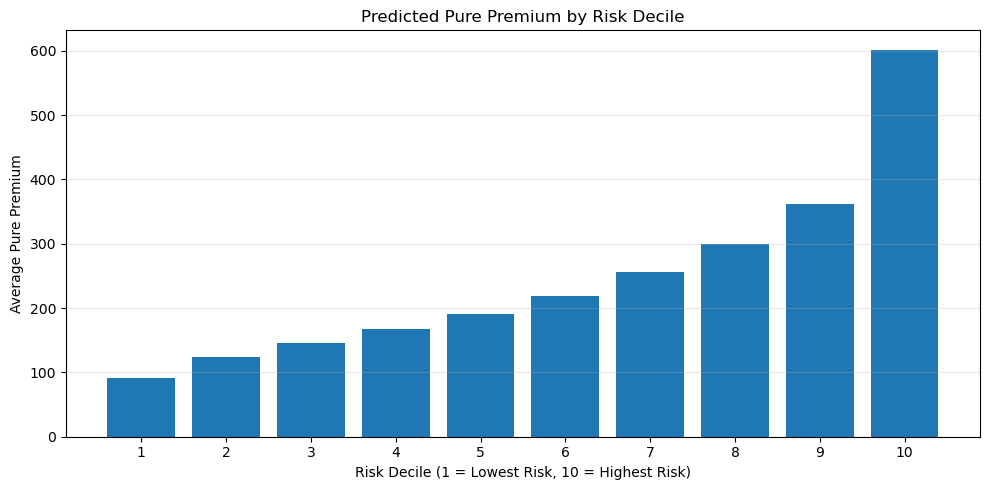

In [105]:
# Plot average predicted pure premium by risk decile

plt.figure(figsize=(10, 5))

plt.bar(
    portfolio_risk_analysis.index.astype(str),
    portfolio_risk_analysis["Average_Pure_Premium"]
)

plt.title("Predicted Pure Premium by Risk Decile")
plt.xlabel("Risk Decile (1 = Lowest Risk, 10 = Highest Risk)")
plt.ylabel("Average Pure Premium")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("Insurance_Claims_Pricing/Pure_Premium_By_Risk_Decile.png", dpi=300)
plt.show()

In [106]:
# Export portfolio risk segmentation
portfolio_risk_analysis.to_csv(
    "Insurance_Claims_Pricing/Portfolio_Risk_Segmentation.csv",
    index=True
)

# Export portfolio predictions
pure_premium_portfolio_test.to_csv(
    "Insurance_Claims_Pricing/Portfolio_Pure_Premium_Predictions.csv",
    index=False
)

print("Files exported successfully!")

Files exported successfully!


## 9. Final Model Performance

In [107]:
# Final model performance summary
# Severity metrics (Gamma GLM / Gradient Boosting) come from the common-test-sample
# comparison in section 6.2-6.3 and are copied here as reported values.

final_results = pd.DataFrame({
    "Component": [
        "Frequency - Poisson GLM",
        "Severity - Gamma GLM",
        "Severity - Gradient Boosting",
        "Pure Premium - Combined Model"
    ],
    "MAE": [
        mean_absolute_error(
            test_data["ClaimNb"],
            test_data["Predicted_ClaimNb"]
        ),
        2020.18,
        1961.40,
        np.nan
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            test_data["ClaimNb"],
            test_data["Predicted_ClaimNb"]
        )),
        8433.56,
        8374.84,
        np.nan
    ],
    "Key_Result": [
        "Predicted claims: 7,194.82",
        "Interpretable actuarial benchmark",
        "Leading severity prediction candidate",
        "Portfolio pure premium: 223.27"
    ]
})

display(final_results)

final_results.to_csv(
    "Insurance_Claims_Pricing/Final_Model_Performance.csv",
    index=False
)

,Component,MAE,RMSE,Key_Result
0,Frequency - Poisson GLM,0.098837,0.237292,"Predicted claims: 7,194.82"
1,Severity - Gamma GLM,2020.180000,8433.560000,Interpretable actuarial benchmark
2,Severity - Gradient Boosting,1961.400000,8374.840000,Leading severity prediction candidate
3,Pure Premium - Combined Model,NaN,NaN,Portfolio pure premium: 223.27


## 10. Outputs

Running the notebook end to end writes the result tables (`*.csv`) and `Pure_Premium_By_Risk_Decile.png` to the working folder. `Portfolio_Pure_Premium_Predictions.csv` (about 20 MB) is regenerated by the notebook and excluded from Git.

# 11. Conclusion and Limitations


## 11.1. Conclusion

This project developed an end-to-end actuarial and machine learning framework for motor insurance claims prediction and pricing using the French freMTPL2 dataset.

The analysis focused on three main components:

- **Claim Frequency:** The Poisson GLM, incorporating exposure as an offset, achieved an MAE of 0.0988 and an RMSE of 0.2373. The model predicted 7,194.82 claims compared with 7,241 observed claims on the test set, corresponding to a slight underestimation of approximately 0.64%.

- **Claim Severity:** Several approaches were evaluated, including Gamma GLM, Lognormal Regression and Histogram-based Gradient Boosting. On the common test sample, Gradient Boosting achieved a lower MAE (1,961.40) than Gamma GLM (2,020.18), showing a modest improvement in predictive accuracy.

- **Pure Premium and Risk Segmentation:** The portfolio-level pure premium was estimated at 223.27 per exposure unit. Risk segmentation revealed a substantial difference between the lowest-risk and highest-risk deciles, with average predicted pure premiums of 91.08 and 601.62, respectively.

Overall, the project illustrates how traditional actuarial models and machine learning techniques can complement each other. GLMs provide an interpretable statistical framework, while machine learning models offer additional flexibility in modelling complex relationships.

## 11.2. Limitations

Despite the results obtained, several limitations should be considered:

1. **Severity Data Coverage:** The severity dataset contains approximately 73.25% of the claims recorded in the frequency dataset. Consequently, the severity analysis is based on a subset of the original claims.

2. **Limited Severity Test Sample:** The common test sample contains approximately 1,080 claims, which may limit the generalisation of severity model comparisons.

3. **Extreme Claims:** Very high claim amounts are difficult to predict accurately and can strongly influence evaluation metrics, particularly RMSE.

4. **Model Calibration:** Calibration analysis revealed differences between predicted and observed claim amounts across risk deciles. In particular, the Gamma GLM showed prediction ratios ranging from approximately 0.52 to 2.13 on the common test sample. Therefore, better predictive accuracy does not necessarily imply perfect calibration.

5. **Validation Strategy:** The models were evaluated using a single train-test split with a fixed random state. Cross-validation and confidence intervals could provide a more robust assessment of model stability.

6. **Pure Premium Scope:** The estimated pure premium represents expected claim cost only. It excludes administrative expenses, commissions, taxes, reinsurance costs and profit margins. It should therefore not be interpreted as the final commercial insurance premium.

## 11.3. Future Improvements

Several extensions could improve this work:

- Apply cross-validation and confidence intervals to assess model robustness.
- Further optimise Gradient Boosting hyperparameters.
- Explore Tweedie GLM models for insurance pricing.
- Investigate separate modelling approaches for large and extreme claims.
- Improve model calibration across risk segments.
- Extend pure premium estimation by incorporating expenses and other pricing components.

## 11.4. Final Remarks

This project provided practical experience in actuarial modelling, statistical analysis, machine learning and insurance risk segmentation. It also highlighted the importance of balancing predictive performance, interpretability and calibration when developing motor insurance pricing models.